In [2]:
import pandas as pd
import numpy as np
from rdkit import Chem
from rdkit.Chem import Descriptors, Lipinski, rdMolDescriptors
from rdkit.Chem import GraphDescriptors
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.linear_model import LassoCV
from sklearn.model_selection import RepeatedKFold

In [3]:
data = pd.read_excel('锡基的收集含c链.xlsx')

In [4]:
import pandas as pd
import numpy as np
from rdkit import Chem
from rdkit.Chem import Descriptors, rdMolDescriptors, Lipinski


smiles_series = data.iloc[:,2].astype(str)

def calc_features(smiles: str) -> dict:
    if pd.isna(smiles) or smiles.strip() == '':
        mol = None
    else:
        mol = Chem.MolFromSmiles(smiles.strip())
    
    if mol is None:
        return {key: np.nan for key in [
            'Heavy_atoms', 'H_Acceptors', 'H_Donors', 'Rot_bonds', 'Mol_Wt',
            'TPSA', 'LogP', 'Complexity',
            'Carbon', 'Hydrogen', 'Oxide', 'Nitrogen', 'Sulfur', 'Halogen'
        ]}
    
    # 基础描述符（不需要加氢）
    heavy_atoms = rdMolDescriptors.CalcNumHeavyAtoms(mol)
    h_acceptors = Lipinski.NumHAcceptors(mol)
    h_donors = Lipinski.NumHDonors(mol)
    rot_bonds = Lipinski.NumRotatableBonds(mol)
    mol_wt = Descriptors.MolWt(mol)
    tpsa = Descriptors.TPSA(mol)
    logp = Descriptors.MolLogP(mol)
    complexity = Descriptors.BertzCT(mol)

    # 原子计数：需加氢以统计总氢原子数
    mol_with_h = Chem.AddHs(mol)
    carbon = hydrogen = oxide = nitrogen = sulfur = halogen = 0
    for atom in mol_with_h.GetAtoms():
        symbol = atom.GetSymbol()
        if symbol == 'C':
            carbon += 1
        elif symbol == 'H':
            hydrogen += 1
        elif symbol == 'O':
            oxide += 1
        elif symbol == 'N':
            nitrogen += 1
        elif symbol == 'S':
            sulfur += 1
        elif symbol in ('F', 'Cl', 'Br', 'I'):
            halogen += 1

    return {
        'Heavy_atoms': heavy_atoms,
        'H_Acceptors': h_acceptors,
        'H_Donors': h_donors,
        'Rot_bonds': rot_bonds,
        'Mol_Wt': mol_wt,
        'TPSA': tpsa,
        'LogP': logp,
        'Complexity': complexity,
        'Carbon': carbon,
        'Hydrogen': hydrogen,
        'Oxide': oxide,
        'Nitrogen': nitrogen,
        'Sulfur': sulfur,
        'Halogen': halogen
    }

features_list = [calc_features(smi) for smi in smiles_series]

# 合并并保存
desc_df = pd.DataFrame(features_list, index=data.index)
data_out = pd.concat([data, desc_df], axis=1)


In [5]:
data_out


,doi,分子名称,SMILES,CONTROL-PCE,PASS-PCE,Sn,Pb,Heavy_atoms,H_Acceptors,H_Donors,...,Mol_Wt,TPSA,LogP,Complexity,Carbon,Hydrogen,Oxide,Nitrogen,Sulfur,Halogen
0,10.1002/adma.202419018,2-BH（2-Bromoethylamine hydrobromide）,C(CBr)N.Br,17.00,18.50,0.3,0.7,5,1,1,...,204.893,26.02,0.9179,2.000000,2,7,0,1,0,2
1,10.1021/acsami.5c09034,4-BBAC（4-bromobenzylamine hydrochloride）,C1=CC(=CC=C1CN)Br.Cl,16.23,18.36,0.3,0.7,10,1,1,...,222.513,26.02,2.3296,171.734728,7,9,0,1,0,2
2,10.1002/adma.202414125,4-ABSA（4-aminobenzenesulfonic acid）,C1=CC(=CC=C1N)S(=O)(=O)O,17.30,20.30,0.4,0.6,11,3,2,...,173.193,80.39,0.5155,322.805989,6,7,3,1,1,0
3,10.1002/adma.202309193,BHA（Benzhydroxamic Acid）,C1=CC=C(C=C1)C(=O)NO,14.34,17.12,0.4,0.6,10,2,2,...,137.138,49.33,0.8056,208.739737,7,7,2,1,0,0
4,10.1002/aenm.202204115,OABF₄（octylammonium tetrafluoroborate）,[B-](F)(F)(F)F.CCCCCCCC[NH3+],20.50,23.70,0.5,0.5,14,0,1,...,217.059,27.64,2.8888,74.701658,8,20,0,1,0,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
93,10.1021/acsenergylett.3c02470,OA（oleic acid）,CCCCCCCC/C=C\\CCCCCCCC(=O)O,20.00,22.40,1.0,0.0,20,1,1,...,282.468,37.30,6.1085,224.192809,18,34,2,0,0,0
94,10.1002/anie.202318133,"F3-TMOS（trimethoxy(3,3,3-trifluoropropyl)silane）",CO[Si](CCC(F)(F)F)(OC)OC,10.65,14.67,1.0,0.0,13,3,0,...,218.247,27.69,1.8169,115.199299,6,13,3,0,0,3
95,10.1002/adfm.202313833,Vanillin,COC1=C(C=CC(=C1)C=O)O,9.60,13.18,1.0,0.0,11,3,1,...,152.149,46.53,1.2133,258.740862,8,8,3,0,0,0
96,10.1016/j.surfin.2023.103478,"MeO-2PACz（2-(3,6-dimethoxycarbazol-9-yl)ethylp...",COC1=CC2=C(C=C1)N(C3=C2C=C(C=C3)OC)CCP(=O)(O)O,7.44,12.16,1.0,0.0,23,4,2,...,335.296,80.92,2.9894,821.928590,16,18,5,1,0,0


In [6]:
y_pass = data_out['PASS-PCE']

In [7]:
data_out.drop(columns=['doi','分子名称','SMILES','PASS-PCE'], inplace=True)

In [8]:
X = data_out
X

,CONTROL-PCE,Sn,Pb,Heavy_atoms,H_Acceptors,H_Donors,Rot_bonds,Mol_Wt,TPSA,LogP,Complexity,Carbon,Hydrogen,Oxide,Nitrogen,Sulfur,Halogen
0,17.00,0.3,0.7,5,1,1,1,204.893,26.02,0.9179,2.000000,2,7,0,1,0,2
1,16.23,0.3,0.7,10,1,1,1,222.513,26.02,2.3296,171.734728,7,9,0,1,0,2
2,17.30,0.4,0.6,11,3,2,1,173.193,80.39,0.5155,322.805989,6,7,3,1,1,0
3,14.34,0.4,0.6,10,2,2,1,137.138,49.33,0.8056,208.739737,7,7,2,1,0,0
4,20.50,0.5,0.5,14,0,1,6,217.059,27.64,2.8888,74.701658,8,20,0,1,0,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
93,20.00,1.0,0.0,20,1,1,15,282.468,37.30,6.1085,224.192809,18,34,2,0,0,0
94,10.65,1.0,0.0,13,3,0,5,218.247,27.69,1.8169,115.199299,6,13,3,0,0,3
95,9.60,1.0,0.0,11,3,1,2,152.149,46.53,1.2133,258.740862,8,8,3,0,0,0
96,7.44,1.0,0.0,23,4,2,5,335.296,80.92,2.9894,821.928590,16,18,5,1,0,0


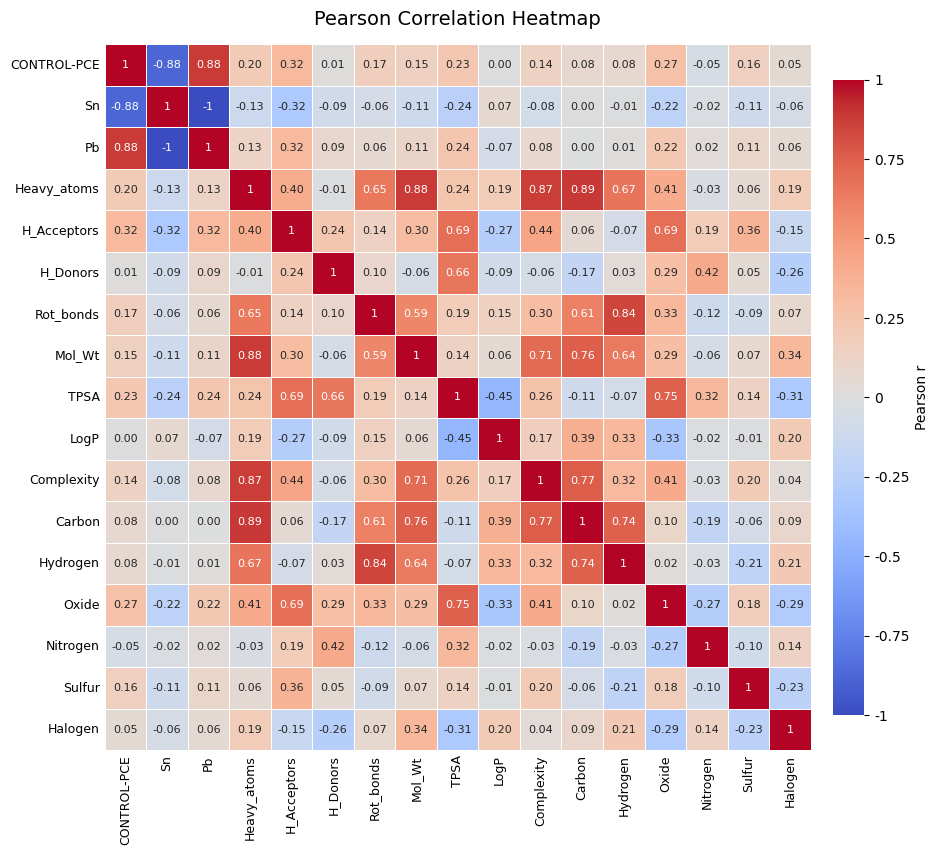

In [9]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FormatStrFormatter

# ==============================
# 1. 全局绘图设置
# ==============================
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['svg.fonttype'] = 'none'

# ==============================
# 2. 计算 Pearson 相关系数
# ==============================
corr = X.corr(method='pearson')

# ==============================
# 3. 自定义数值显示
# ==============================
labels = np.array([
    [f'{v:.2f}' if np.isfinite(v) else '' for v in row]
    for row in corr.to_numpy()
], dtype=object)

# 对角线显示整数 1
np.fill_diagonal(labels, '1')

# 其他精确为 1 或 -1 的相关系数显示整数
values = corr.to_numpy()

labels[np.isfinite(values) & np.isclose(values, 1)] = '1'
labels[np.isfinite(values) & np.isclose(values, -1)] = '-1'

# 避免显示 -0.00
labels[labels == '-0.00'] = '0.00'

# ==============================
# 4. 绘制完整相关性热力图
# ==============================
fig, ax = plt.subplots(figsize=(10, 8.5))

sns.heatmap(
    corr,
    annot=labels,
    fmt='',
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.4,
    linecolor='white',
    annot_kws={'size': 8},
    cbar_kws={
        'shrink': 0.9,
        'pad': 0.025,
        'label': 'Pearson r'
    },
    ax=ax
)

# ==============================
# 5. 坐标轴与字体
# ==============================
ax.set_title(
    'Pearson Correlation Heatmap',
    fontsize=14,
    pad=14
)

ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation=90,
    ha='center',
    fontsize=9
)

ax.set_yticklabels(
    ax.get_yticklabels(),
    rotation=0,
    fontsize=9
)

ax.tick_params(axis='both', length=0)

# ==============================
# 6. 色条刻度格式
# ==============================
cbar = ax.collections[0].colorbar
cbar.ax.yaxis.set_major_formatter(
    FormatStrFormatter('%g')
)

# ==============================
# 7. 保存图片
# ==============================
plt.tight_layout()

plt.savefig(
    'pearson_heatmap.png',
    dpi=600,
    bbox_inches='tight',
    facecolor='white'
)

plt.savefig(
    'pearson_heatmap.svg',
    bbox_inches='tight',
    facecolor='white'
)

plt.show()


In [10]:
# ① 先删除不需要的特征
X.drop(columns=['Heavy_atoms'], inplace=True)

# ② 再拟合并归一化 —— 此时 scaler 只记录 16个特征（不含 Heavy_atoms）
scaler = MinMaxScaler()  
X_NOR = pd.DataFrame(scaler.fit_transform(X), columns=X.columns) 
X_NOR

,CONTROL-PCE,Sn,Pb,H_Acceptors,H_Donors,Rot_bonds,Mol_Wt,TPSA,LogP,Complexity,Carbon,Hydrogen,Oxide,Nitrogen,Sulfur,Halogen
0,0.696970,0.000000,1.000000,0.111111,0.125,0.066667,0.219143,0.109975,0.744922,0.001685,0.058824,0.184211,0.000000,0.166667,0.00,0.333333
1,0.655303,0.000000,1.000000,0.111111,0.125,0.066667,0.245259,0.109975,0.814296,0.144648,0.205882,0.236842,0.000000,0.166667,0.00,0.333333
2,0.713203,0.142857,0.857143,0.333333,0.250,0.066667,0.172157,0.339772,0.725148,0.271893,0.176471,0.184211,0.250000,0.166667,0.25,0.000000
3,0.553030,0.142857,0.857143,0.222222,0.250,0.066667,0.118717,0.208495,0.739404,0.175817,0.205882,0.184211,0.166667,0.166667,0.00,0.000000
4,0.886364,0.285714,0.714286,0.000000,0.125,0.400000,0.237175,0.116822,0.841777,0.062920,0.235294,0.526316,0.000000,0.166667,0.00,0.666667
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
93,0.859307,1.000000,0.000000,0.111111,0.125,1.000000,0.334124,0.157650,1.000000,0.188833,0.529412,0.894737,0.166667,0.000000,0.00,0.000000
94,0.353355,1.000000,0.000000,0.333333,0.000,0.333333,0.238936,0.117033,0.789101,0.097030,0.176471,0.342105,0.250000,0.000000,0.00,0.500000
95,0.296537,1.000000,0.000000,0.333333,0.125,0.133333,0.140966,0.196661,0.759439,0.217932,0.235294,0.210526,0.250000,0.000000,0.00,0.000000
96,0.179654,1.000000,0.000000,0.444444,0.250,0.333333,0.412426,0.342012,0.846720,0.692293,0.470588,0.473684,0.416667,0.166667,0.00,0.000000


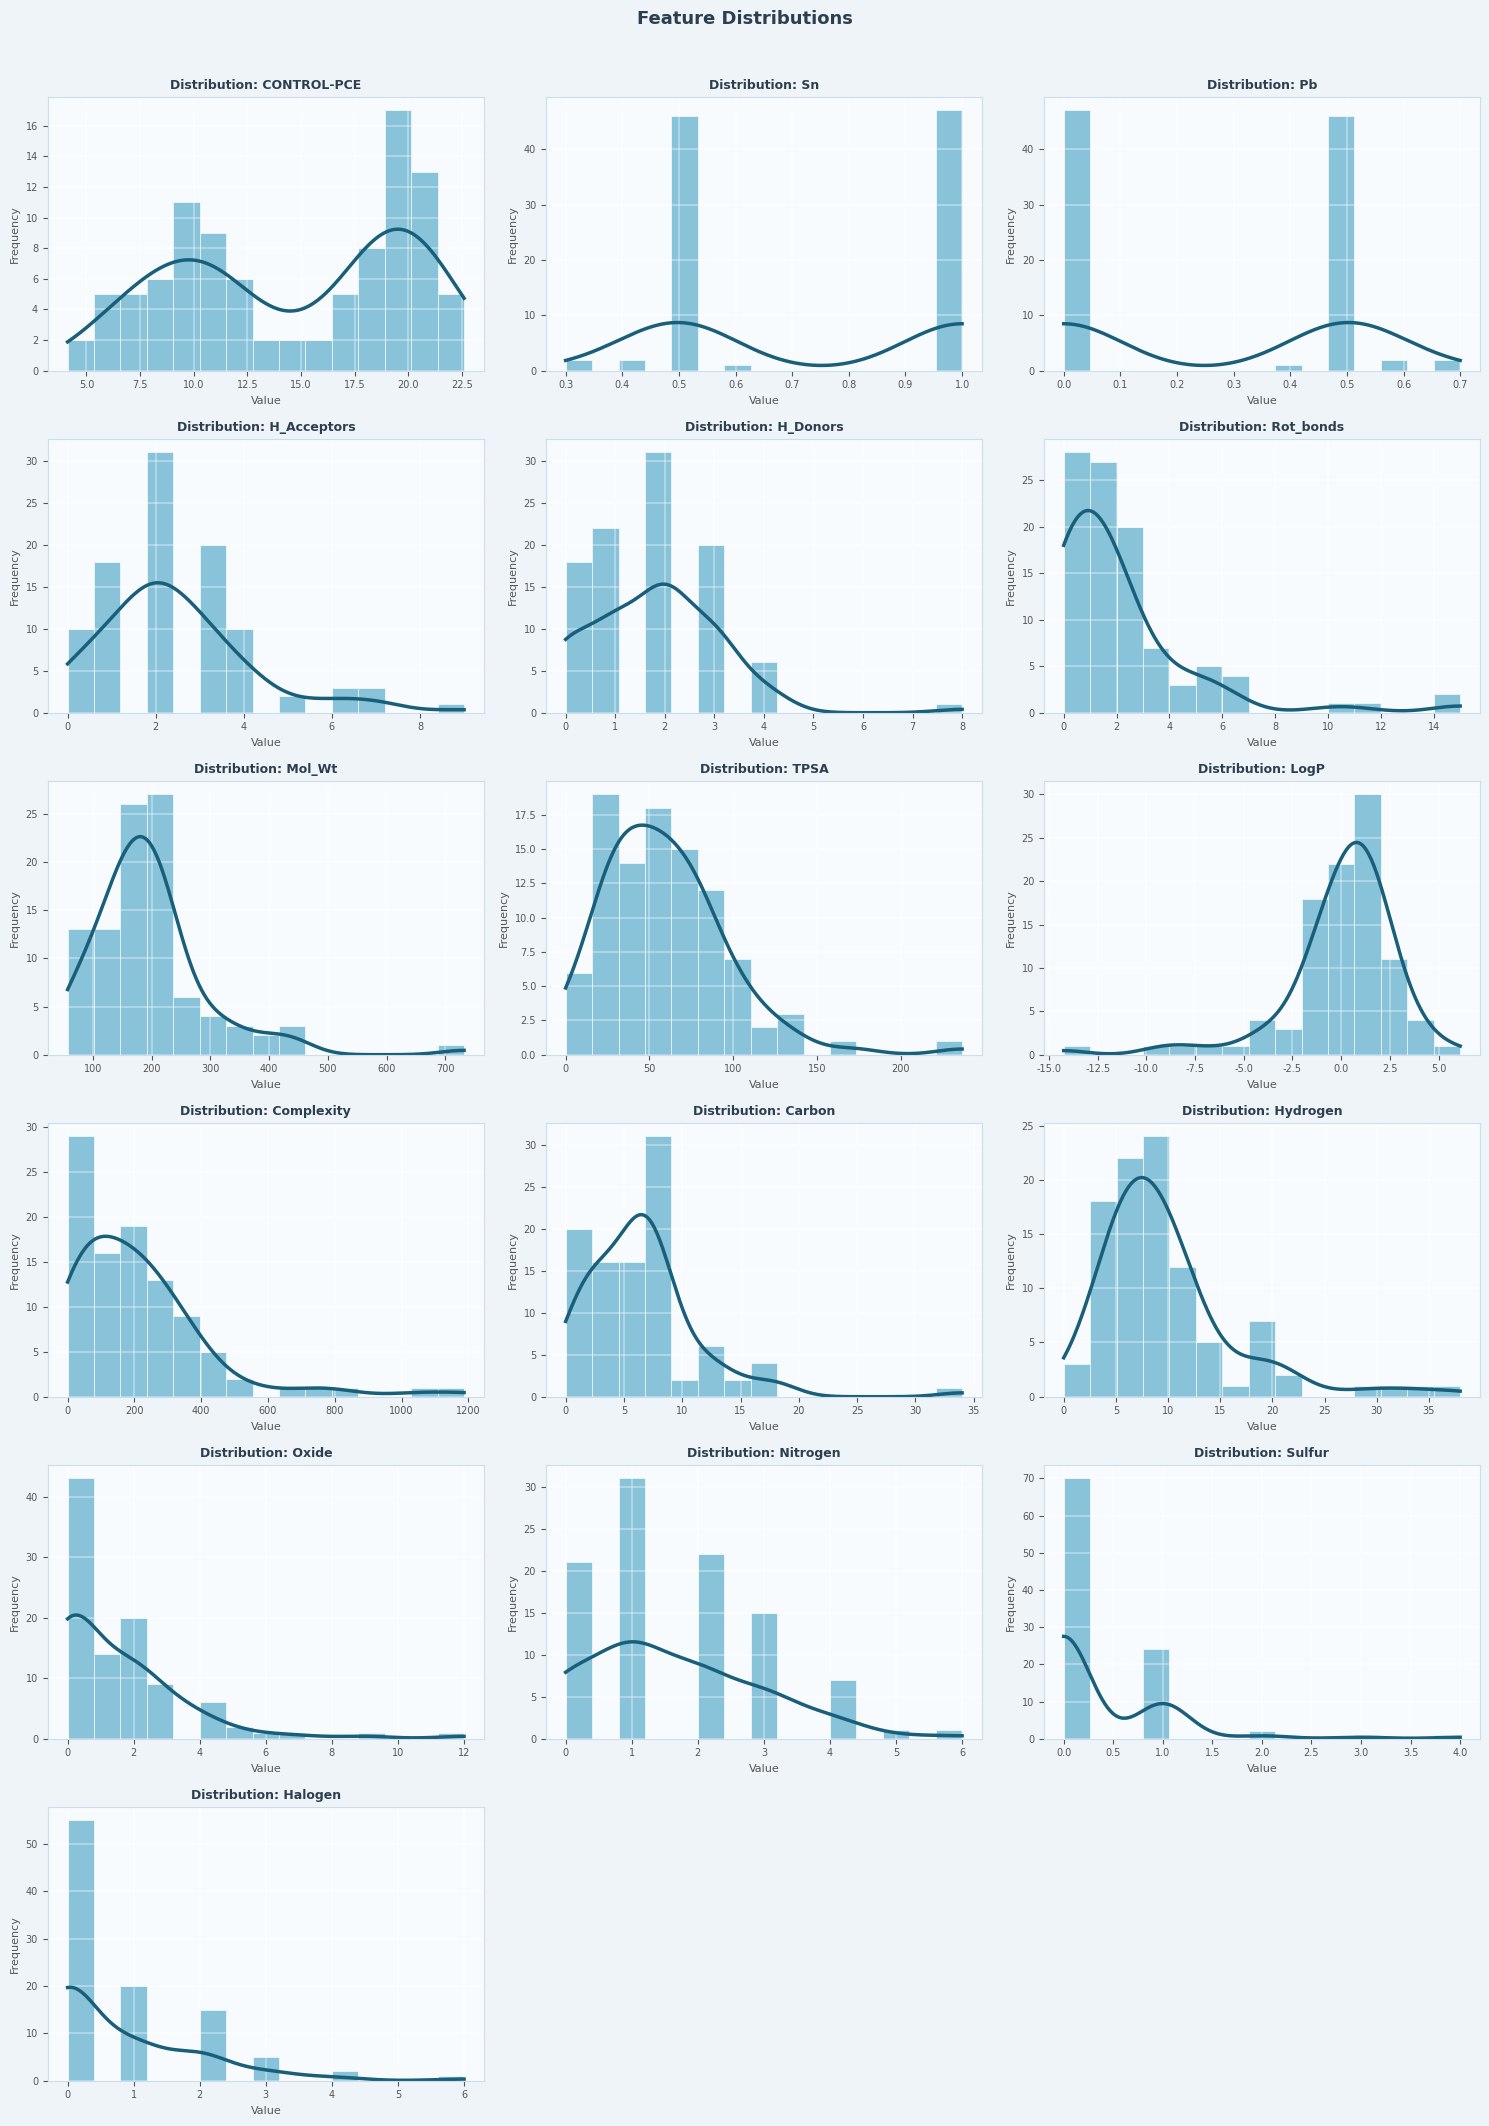

In [11]:
  import pandas as pd
  import numpy as np
  import matplotlib.pyplot as plt
  from scipy.stats import gaussian_kde

  cols = X.columns.tolist()
  n_cols = 3
  n_rows = int(np.ceil(len(cols) / n_cols))

  fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, n_rows * 3.5))
  axes = axes.flatten()

  bar_color = '#74B9D4'   # 清爽蓝
  kde_color = '#1A5F7A'   # 深海蓝

  for i, col in enumerate(cols):
      ax = axes[i]
      data = X[col].dropna()

      ax.hist(data, bins=15, color=bar_color, edgecolor='white', linewidth=0.5,
              density=False, alpha=0.85)

      kde = gaussian_kde(data, bw_method='scott')
      x_range = np.linspace(data.min(), data.max(), 300)
      kde_values = kde(x_range)
      scale = len(data) * (data.max() - data.min()) / 15
      ax.plot(x_range, kde_values * scale, color=kde_color, linewidth=2.5)

      ax.set_title(f'Distribution: {col}', fontsize=9, color='#2C3E50', fontweight='bold')
      ax.set_xlabel('Value', fontsize=8, color='#555')
      ax.set_ylabel('Frequency', fontsize=8, color='#555')
      ax.tick_params(labelsize=7, colors='#555')
      ax.set_facecolor('#F8FBFD')
      ax.grid(True, alpha=0.4, color='white', linewidth=1.2)
      for spine in ax.spines.values():
          spine.set_edgecolor('#CCDDEE')

  for j in range(len(cols), len(axes)):
      axes[j].set_visible(False)

  fig.patch.set_facecolor('#EEF4F8')
  plt.suptitle('Feature Distributions', fontsize=13, color='#2C3E50', fontweight='bold', y=1.01)
  plt.tight_layout()
  plt.savefig('distribution_plots.png', dpi=150, bbox_inches='tight')
  plt.show()

正在进行交叉验证自动调参，请稍候...
调参完成！最佳 alpha 值为: 0.05

GPR (自动调参后) 模型性能评估
训练集性能指标:
  R² (决定系数): 0.9606
  R (相关系数): 0.9802
  MAE (平均绝对误差): 0.7561
  RMSE (均方根误差): 0.9994

测试集性能指标:
  R² (决定系数): 0.9412
  R (相关系数): 0.9789
  MAE (平均绝对误差): 0.8141
  RMSE (均方根误差): 1.0447

训练集样本数: 78 | 测试集样本数: 20
训练集 PCE 范围: 8.11 - 24.50
测试集 PCE 范围: 10.86 - 24.90


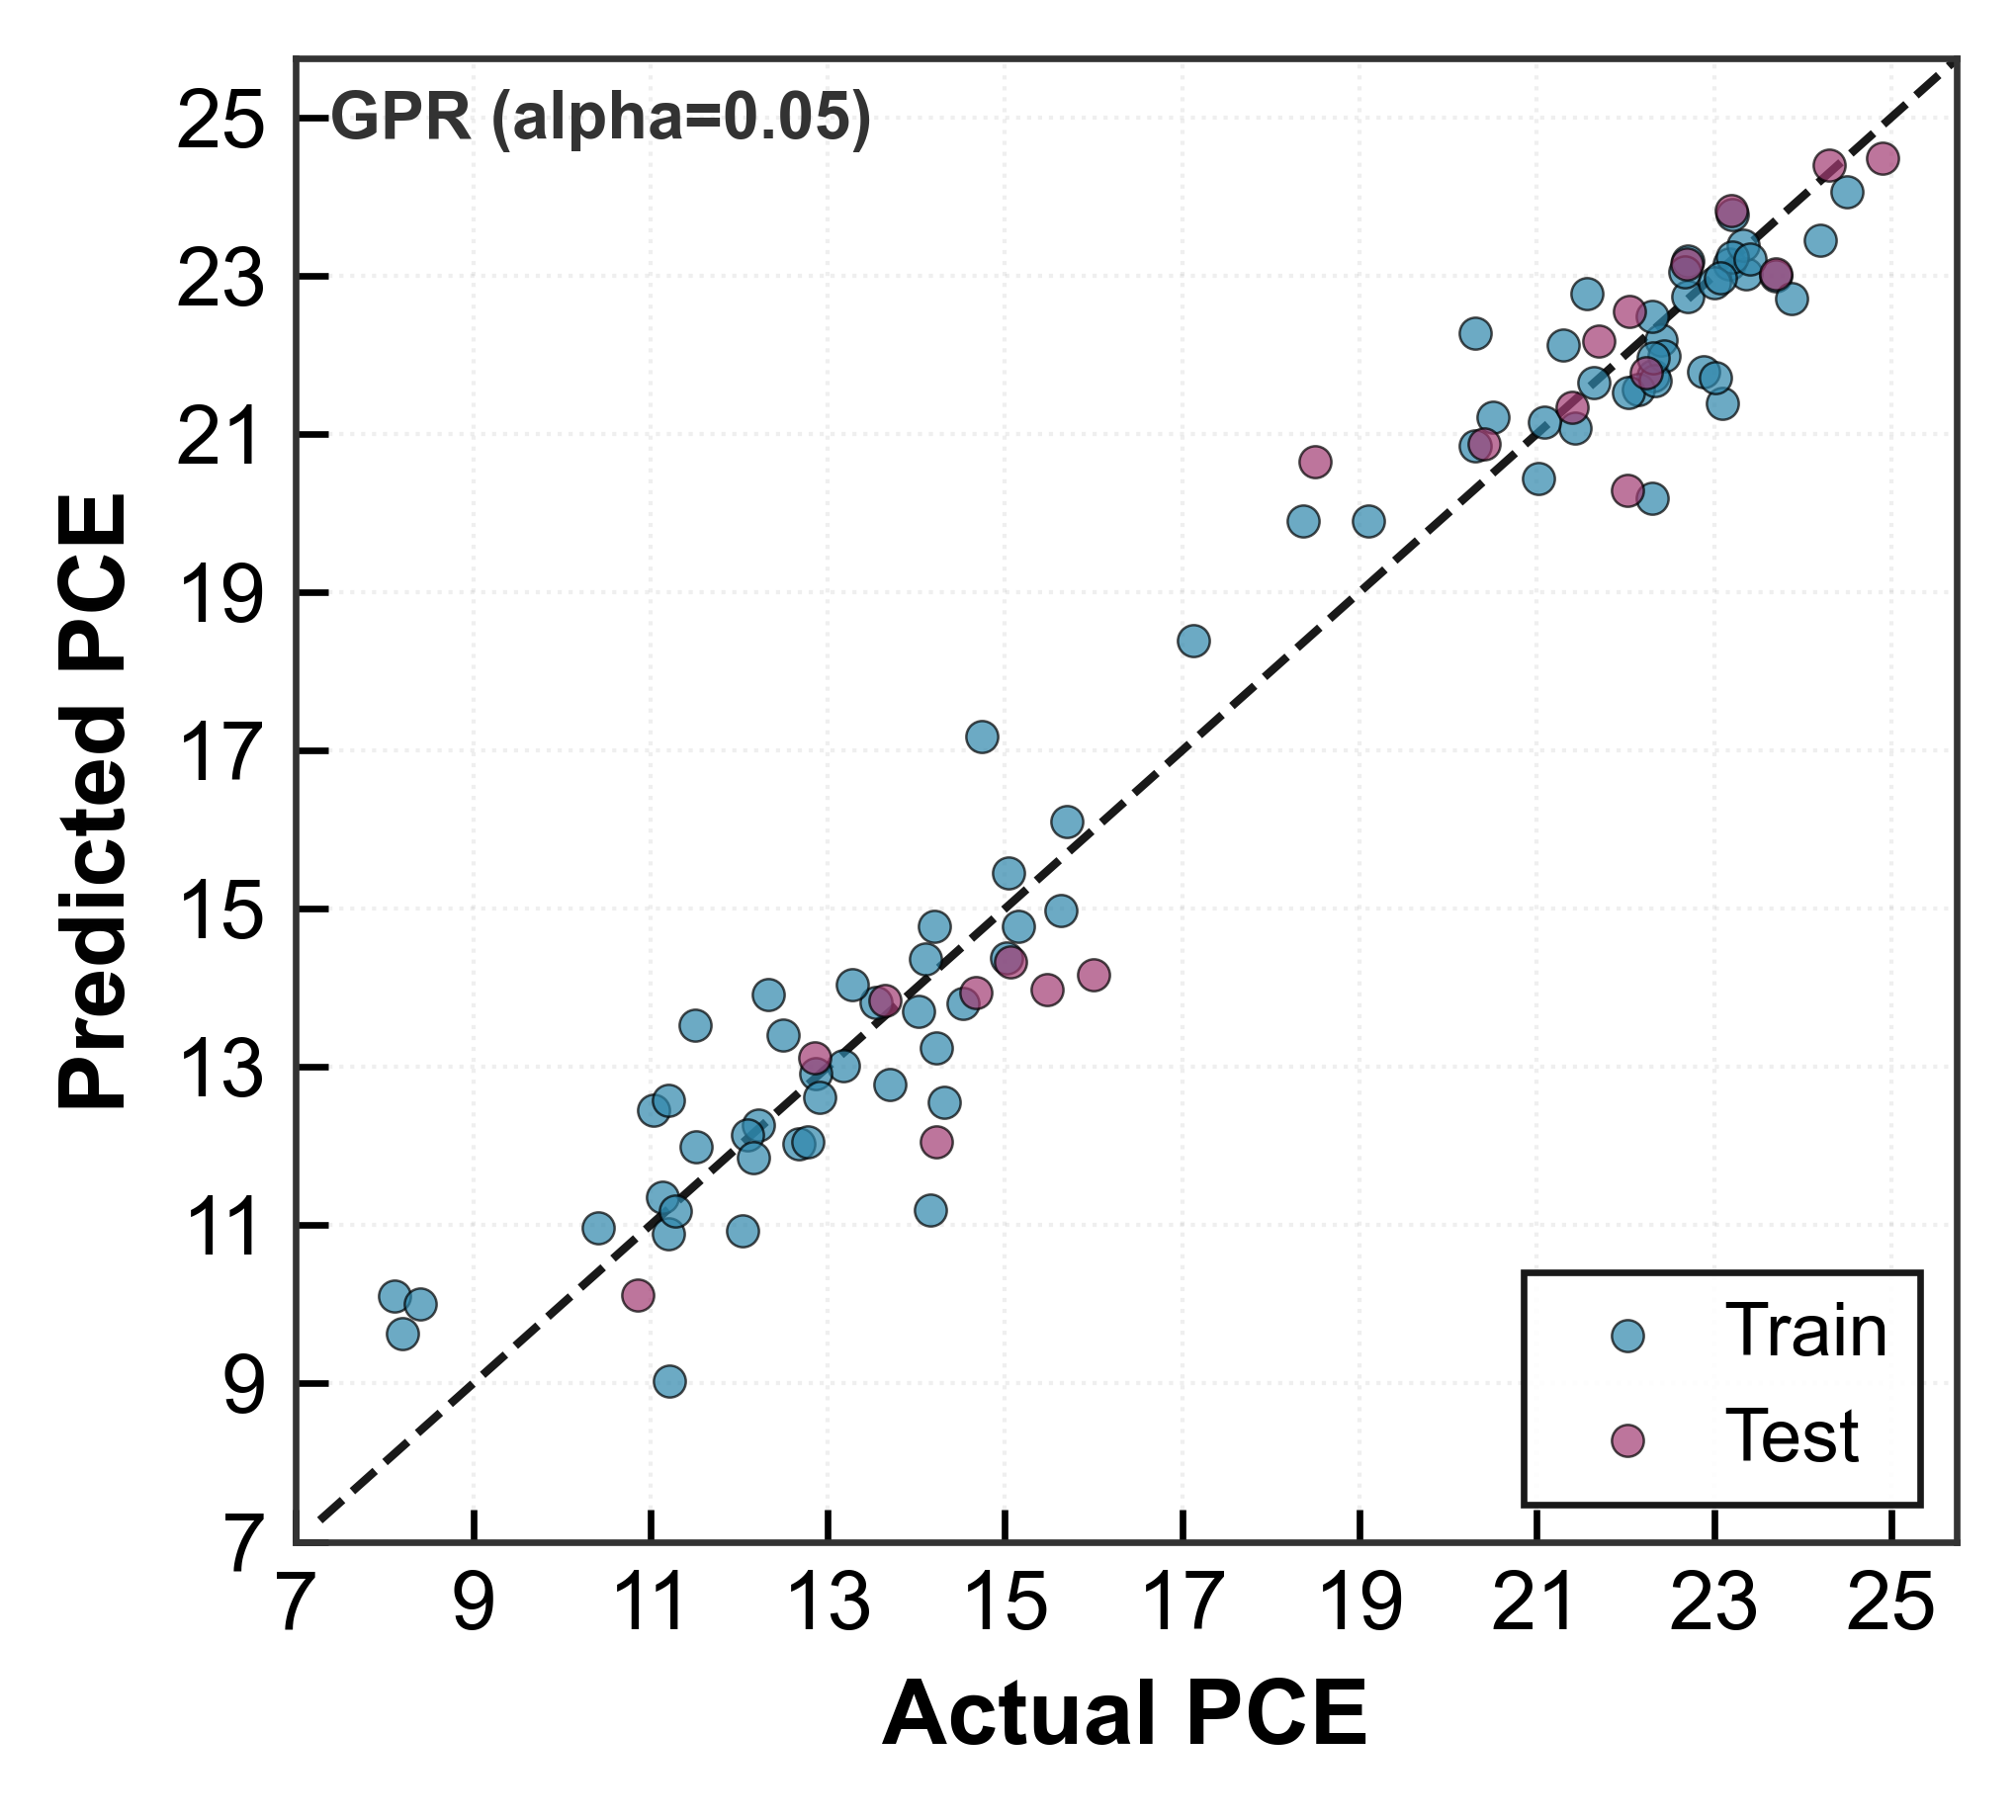

In [12]:
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel as C
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from scipy.stats import pearsonr
import matplotlib.pyplot as plt
import numpy as np

# ========== 统一风格设置（与 SHAP 图完全一致）==========
plt.rcParams.update({
    'font.family': 'Arial',
    'font.size': 10,
    'axes.labelsize': 11,
    'axes.titlesize': 12,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'axes.linewidth': 0.8,
    'xtick.major.width': 0.8,
    'ytick.major.width': 0.8,
    'xtick.major.size': 4,
    'ytick.major.size': 4,
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'xtick.top': True,
    'ytick.right': True,
    'savefig.dpi': 600,
    'savefig.pad_inches': 0.1  # 固定留白
})

# 划分训练集和测试集 (注意：运行前请确保 X_NOR 和 y_pass 已定义)
X_train, X_test, y_train, y_test = train_test_split(X_NOR, y_pass, test_size=0.2, random_state=42)

# ========== 定义与自动调参 (GridSearchCV) ==========
print("正在进行交叉验证自动调参，请稍候...")

# 1. 定义核函数 (GPR 内部会自动优化 length_scale)
kernel = C(1.0, (1e-3, 1e3)) * RBF(length_scale=10.0, length_scale_bounds=(1e-2, 1e2))

# 2. 定义基础 GPR 模型
base_gpr = GaussianProcessRegressor(
    kernel=kernel, 
    n_restarts_optimizer=10, 
    normalize_y=True, 
    random_state=42
)

# 3. 定义要搜索的 alpha 参数网格 (覆盖从极小噪声到较大噪声)
param_grid = {
    'alpha': [1e-4, 1e-3, 1e-2, 0.05, 0.1, 0.5, 1.0, 2.0, 5.0]
}

# 4. 使用 5 折交叉验证寻找最佳 alpha
grid_search = GridSearchCV(
    estimator=base_gpr,
    param_grid=param_grid,
    cv=5, 
    scoring='neg_mean_squared_error', # 寻找 MSE 最小的参数
    n_jobs=-1 # 开启多核并行加速
)

# 5. 执行搜索并拟合
grid_search.fit(X_train, y_train)

# 获取最佳模型和最佳参数
best_gpr = grid_search.best_estimator_
best_alpha = grid_search.best_params_['alpha']

print(f"调参完成！最佳 alpha 值为: {best_alpha}")

# ========== 预测 ==========
y_pred = best_gpr.predict(X_test)
y_train_pred = best_gpr.predict(X_train)

# ========== 计算并输出性能指标 ==========
print("\n" + "=" * 60)
print("GPR (自动调参后) 模型性能评估")
print("=" * 60)

# 训练集指标
train_r2 = r2_score(y_train, y_train_pred)
train_r, _ = pearsonr(y_train, y_train_pred)
train_mae = mean_absolute_error(y_train, y_train_pred)
train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))

# 测试集指标
test_r2 = r2_score(y_test, y_pred)
test_r, _ = pearsonr(y_test, y_pred)
test_mae = mean_absolute_error(y_test, y_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"训练集性能指标:")
print(f"  R² (决定系数): {train_r2:.4f}")
print(f"  R (相关系数): {train_r:.4f}")
print(f"  MAE (平均绝对误差): {train_mae:.4f}")
print(f"  RMSE (均方根误差): {train_rmse:.4f}")
print("")
print(f"测试集性能指标:")
print(f"  R² (决定系数): {test_r2:.4f}")
print(f"  R (相关系数): {test_r:.4f}")
print(f"  MAE (平均绝对误差): {test_mae:.4f}")
print(f"  RMSE (均方根误差): {test_rmse:.4f}")
print("")
print(f"训练集样本数: {len(y_train)} | 测试集样本数: {len(y_test)}")
print(f"训练集 PCE 范围: {y_train.min():.2f} - {y_train.max():.2f}")
print(f"测试集 PCE 范围: {y_test.min():.2f} - {y_test.max():.2f}")
print("=" * 60)

# ========== 固定绘图区域参数（与 SHAP 图一致）==========
FIG_WIDTH, FIG_HEIGHT = 3.5, 3.0      # 总画布尺寸
PLOT_WIDTH, PLOT_HEIGHT = 2.8, 2.5    # 绘图区域尺寸
LEFT_MARGIN = 0.35
BOTTOM_MARGIN = 0.25

# 创建图形
fig, ax = plt.subplots(figsize=(FIG_WIDTH, FIG_HEIGHT), dpi=600)

# ✅ 手动设置绘图区域位置（关键！）
ax.set_position([
    LEFT_MARGIN / FIG_WIDTH,           # left
    BOTTOM_MARGIN / FIG_HEIGHT,        # bottom
    PLOT_WIDTH / FIG_WIDTH,            # width
    PLOT_HEIGHT / FIG_HEIGHT           # height
])

# 颜色
train_color = '#2E86AB'
test_color = '#A23B72'

# 绘制散点
ax.scatter(y_train, y_train_pred, color=train_color, alpha=0.7, 
           s=15, edgecolors='k', linewidth=0.3, label='Train', zorder=3)
ax.scatter(y_test, y_pred, color=test_color, alpha=0.7, 
           s=15, edgecolors='k', linewidth=0.3, label='Test', zorder=3)

# 理想线
min_val = min(y_train.min(), y_test.min())
max_val = max(y_train.max(), y_test.max())
margin = (max_val - min_val) * 0.05
plot_range = [min_val - margin, max_val + margin]
ax.plot(plot_range, plot_range, 'k--', linewidth=1.0, alpha=0.9, zorder=2)

# ✅ 设置 x/y 轴范围一致
ax.set_xlim(plot_range)
ax.set_ylim(plot_range)

# ✅ 设置刻度（步长为 2）
ticks = np.arange(int(plot_range[0]), int(plot_range[1]) + 1, 2)
ax.set_xticks(ticks)
ax.set_yticks(ticks)

# 刻度线：仅左+下
ax.tick_params(axis='x', which='both', top=False, bottom=True)
ax.tick_params(axis='y', which='both', right=False, left=True)

# 坐标轴标签
ax.set_xlabel('Actual PCE', fontweight='bold', fontsize=11)
ax.set_ylabel('Predicted PCE', fontweight='bold', fontsize=11)

# 边框样式
for spine in ax.spines.values():
    spine.set_linewidth(0.8)
    spine.set_color('#333333')

# 网格
ax.grid(True, alpha=0.2, linestyle=':', linewidth=0.5, zorder=1)

# 图例（右下角）
legend = ax.legend(
    frameon=True,
    fancybox=False,
    edgecolor='black',
    facecolor='white',
    framealpha=0.9,
    loc='lower right',
    handletextpad=0.3,
    columnspacing=0.8,
    fontsize=9
)
legend.get_frame().set_linewidth(0.8)

# 添加 GPR 标识（左上角）
ax.text(0.02, 0.98, f'GPR (alpha={best_alpha})', transform=ax.transAxes,
        fontsize=8, fontweight='bold', ha='left', va='top',
        color='#333333', zorder=5)

# ✅ 不使用 plt.tight_layout()！手动位置已固定

plt.show()

In [13]:
from sklearn.model_selection import cross_validate, KFold
import pandas as pd
import numpy as np

# 1. 定义交叉验证折数（5折是最常用的）
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# 2. 定义要评估的指标
scoring_metrics = {
    'r2': 'r2',
    'rmse': 'neg_root_mean_squared_error',
    'mae': 'neg_mean_absolute_error'
}



# ---------- B. GPR 交叉验证 ----------
print("正在执行 GPR 5折交叉验证...")
# 使用自动调参后的最佳模型 best_gpr
cv_results_gpr = cross_validate(
    best_gpr, X_NOR, y_pass, 
    cv=kf, scoring=scoring_metrics, n_jobs=-1
)

# 3. 整理结果并打印
def summarize_cv(results, model_name):
    print(f"\n--- {model_name} 交叉验证汇总 ---")
    print(f"R²:   {results['test_r2'].mean():.4f} (±{results['test_r2'].std():.4f})")
    print(f"RMSE: {-results['test_rmse'].mean():.4f} (±{results['test_rmse'].std():.4f})")
    print(f"MAE:  {-results['test_mae'].mean():.4f} (±{results['test_mae'].std():.4f})")


summarize_cv(cv_results_gpr, "GPR (ARD)")

# 4. (可选) 将结果对比保存为表格，方便直接贴进论文
df_cv_compare = pd.DataFrame({
    'Metric': ['R2', 'RMSE', 'MAE'],
    
    'GPR_Mean': [
        cv_results_gpr['test_r2'].mean(), 
        -cv_results_gpr['test_rmse'].mean(), 
        -cv_results_gpr['test_mae'].mean()
    ]
})
display(df_cv_compare)

正在执行 GPR 5折交叉验证...

--- GPR (ARD) 交叉验证汇总 ---
R²:   0.9405 (±0.0050)
RMSE: 1.1504 (±0.0886)
MAE:  0.8979 (±0.0982)


,Metric,GPR_Mean
0,R2,0.940490
1,RMSE,1.150418
2,MAE,0.897856


d:\Program Files (x86)\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


正在计算 SHAP 值，GPR 模型耗时较长，请耐心等待...


100%|██████████| 98/98 [00:26<00:00,  3.68it/s]


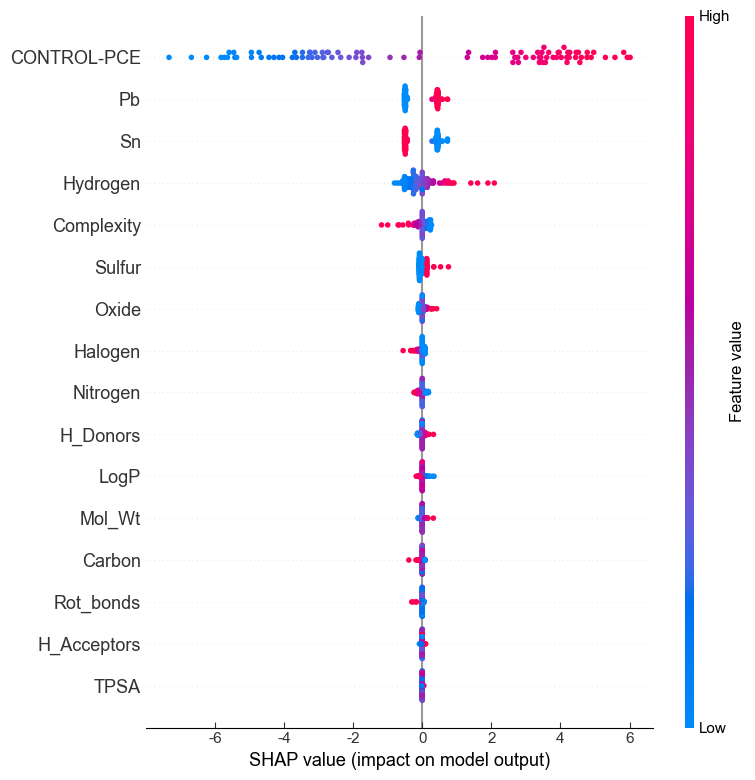

In [14]:
import shap
import matplotlib.pyplot as plt

# 1. 准备背景数据集 (Background Data)
# 使用 shap.sample 随机抽取 50 个样本作为背景参考，极大加快计算速度
# 如果你的总样本量本来就不大（比如只有 100 多个），这里可以设为 30-50
background_data = shap.sample(X_NOR, 50) 

# 2. 初始化 KernelExplainer
# 注意：第一个参数必须传入模型的 predict 方法 (best_gpr.predict)
explainer = shap.KernelExplainer(best_gpr.predict, background_data)

# 3. 计算 SHAP 值
print("正在计算 SHAP 值，GPR 模型耗时较长，请耐心等待...")
# 如果 X_NOR 还是太大导致这一步太慢，你可以考虑只解释测试集： explainer.shap_values(X_test)
shap_values = explainer.shap_values(X_NOR)

# 4. 绘制 SHAP 摘要图
# 建议显式声明一下画布大小，防止挤压
plt.figure(figsize=(8, 5)) 

shap.summary_plot(
    shap_values,
    X_NOR,
    feature_names=X_NOR.columns,
    show=False  # ← 关键！防止自动弹出或重置
)

# 5. 紧接着保存
# plt.savefig(os.path.join(output_dir, 'GPR_SHAP_plot.png'), dpi=600, bbox_inches='tight')

plt.show()

正在计算条形图所需的 SHAP 值，请耐心等待...


100%|██████████| 98/98 [00:27<00:00,  3.57it/s]


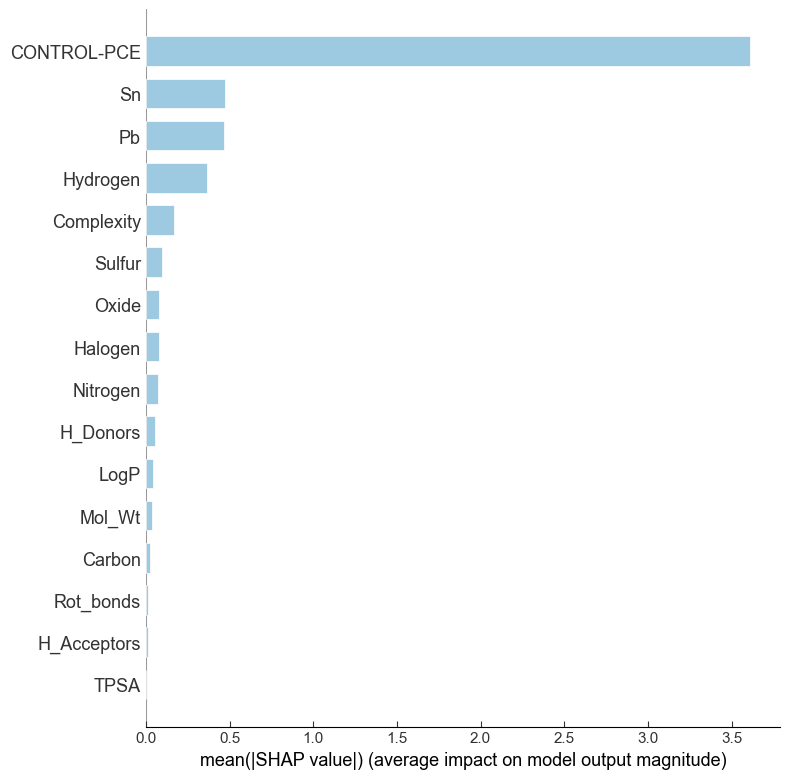

In [15]:
import shap
import matplotlib.pyplot as plt

# 1. 准备背景数据集 (Background Data)
# 因为 GPR 属于黑盒模型，必须用 KernelExplainer 并配合背景数据来加速计算
background_data = shap.sample(X_NOR, 50) 

# 2. 初始化 KernelExplainer (传入 GPR 模型的 predict 方法)
explainer = shap.KernelExplainer(best_gpr.predict, background_data)

# 3. 计算 SHAP 值
print("正在计算条形图所需的 SHAP 值，请耐心等待...")
shap_values = explainer.shap_values(X_NOR)

# 建议显式设置一下画布大小，让条形图比例更好看
plt.figure(figsize=(8, 5))

# 4. 绘制默认条形图（show=False）
shap.summary_plot(
    shap_values,
    X_NOR,
    feature_names=X_NOR.columns,
    plot_type="bar",
    show=False
)

# 5. 获取当前 axes 进行颜色自定义
ax = plt.gca()

# 找到所有 bar（水平条形图是 .patches）
for bar in ax.patches:
    bar.set_color('#9ecae1')      # 填充色
    bar.set_edgecolor('w')        # 边框无颜色（可选）
    bar.set_linewidth(0.5)        # 边框线宽（可选）

# 6. 保存 (名字已帮您改成了 GPR)
# plt.savefig(os.path.join(output_dir, 'GPR_SHAP_bar.png'), dpi=600, bbox_inches='tight')

plt.show()

训练 RBF-GPR 模型...
训练完成！核函数: 3.9**2 * RBF(length_scale=5.3)

计算 SHAP 值（PermutationExplainer）...


PermutationExplainer explainer: 79it [00:10,  5.58it/s]                         


SHAP 矩阵形状: (78, 16)

各特征 SHAP 值范围：
  CONTROL-PCE         : [-6.9558, 5.5998]
  Sn                  : [-0.5887, 0.9523]
  Pb                  : [-0.5887, 0.9524]
  H_Acceptors         : [-0.0756, 0.1528]
  H_Donors            : [-0.1131, 0.2815]
  Rot_bonds           : [-0.0440, 0.2827]
  Mol_Wt              : [-0.0682, 0.2224]
  TPSA                : [-0.0633, 0.0878]
  LogP                : [-0.0952, 0.2117]
  Complexity          : [-1.0453, 0.2281]
  Carbon              : [-0.2062, 0.0496]
  Hydrogen            : [-0.6037, 1.5909]
  Oxide               : [-0.0660, 0.2691]
  Nitrogen            : [-0.2756, 0.1646]
  Sulfur              : [-0.0660, 0.5129]
  Halogen             : [-0.2676, 0.0571]


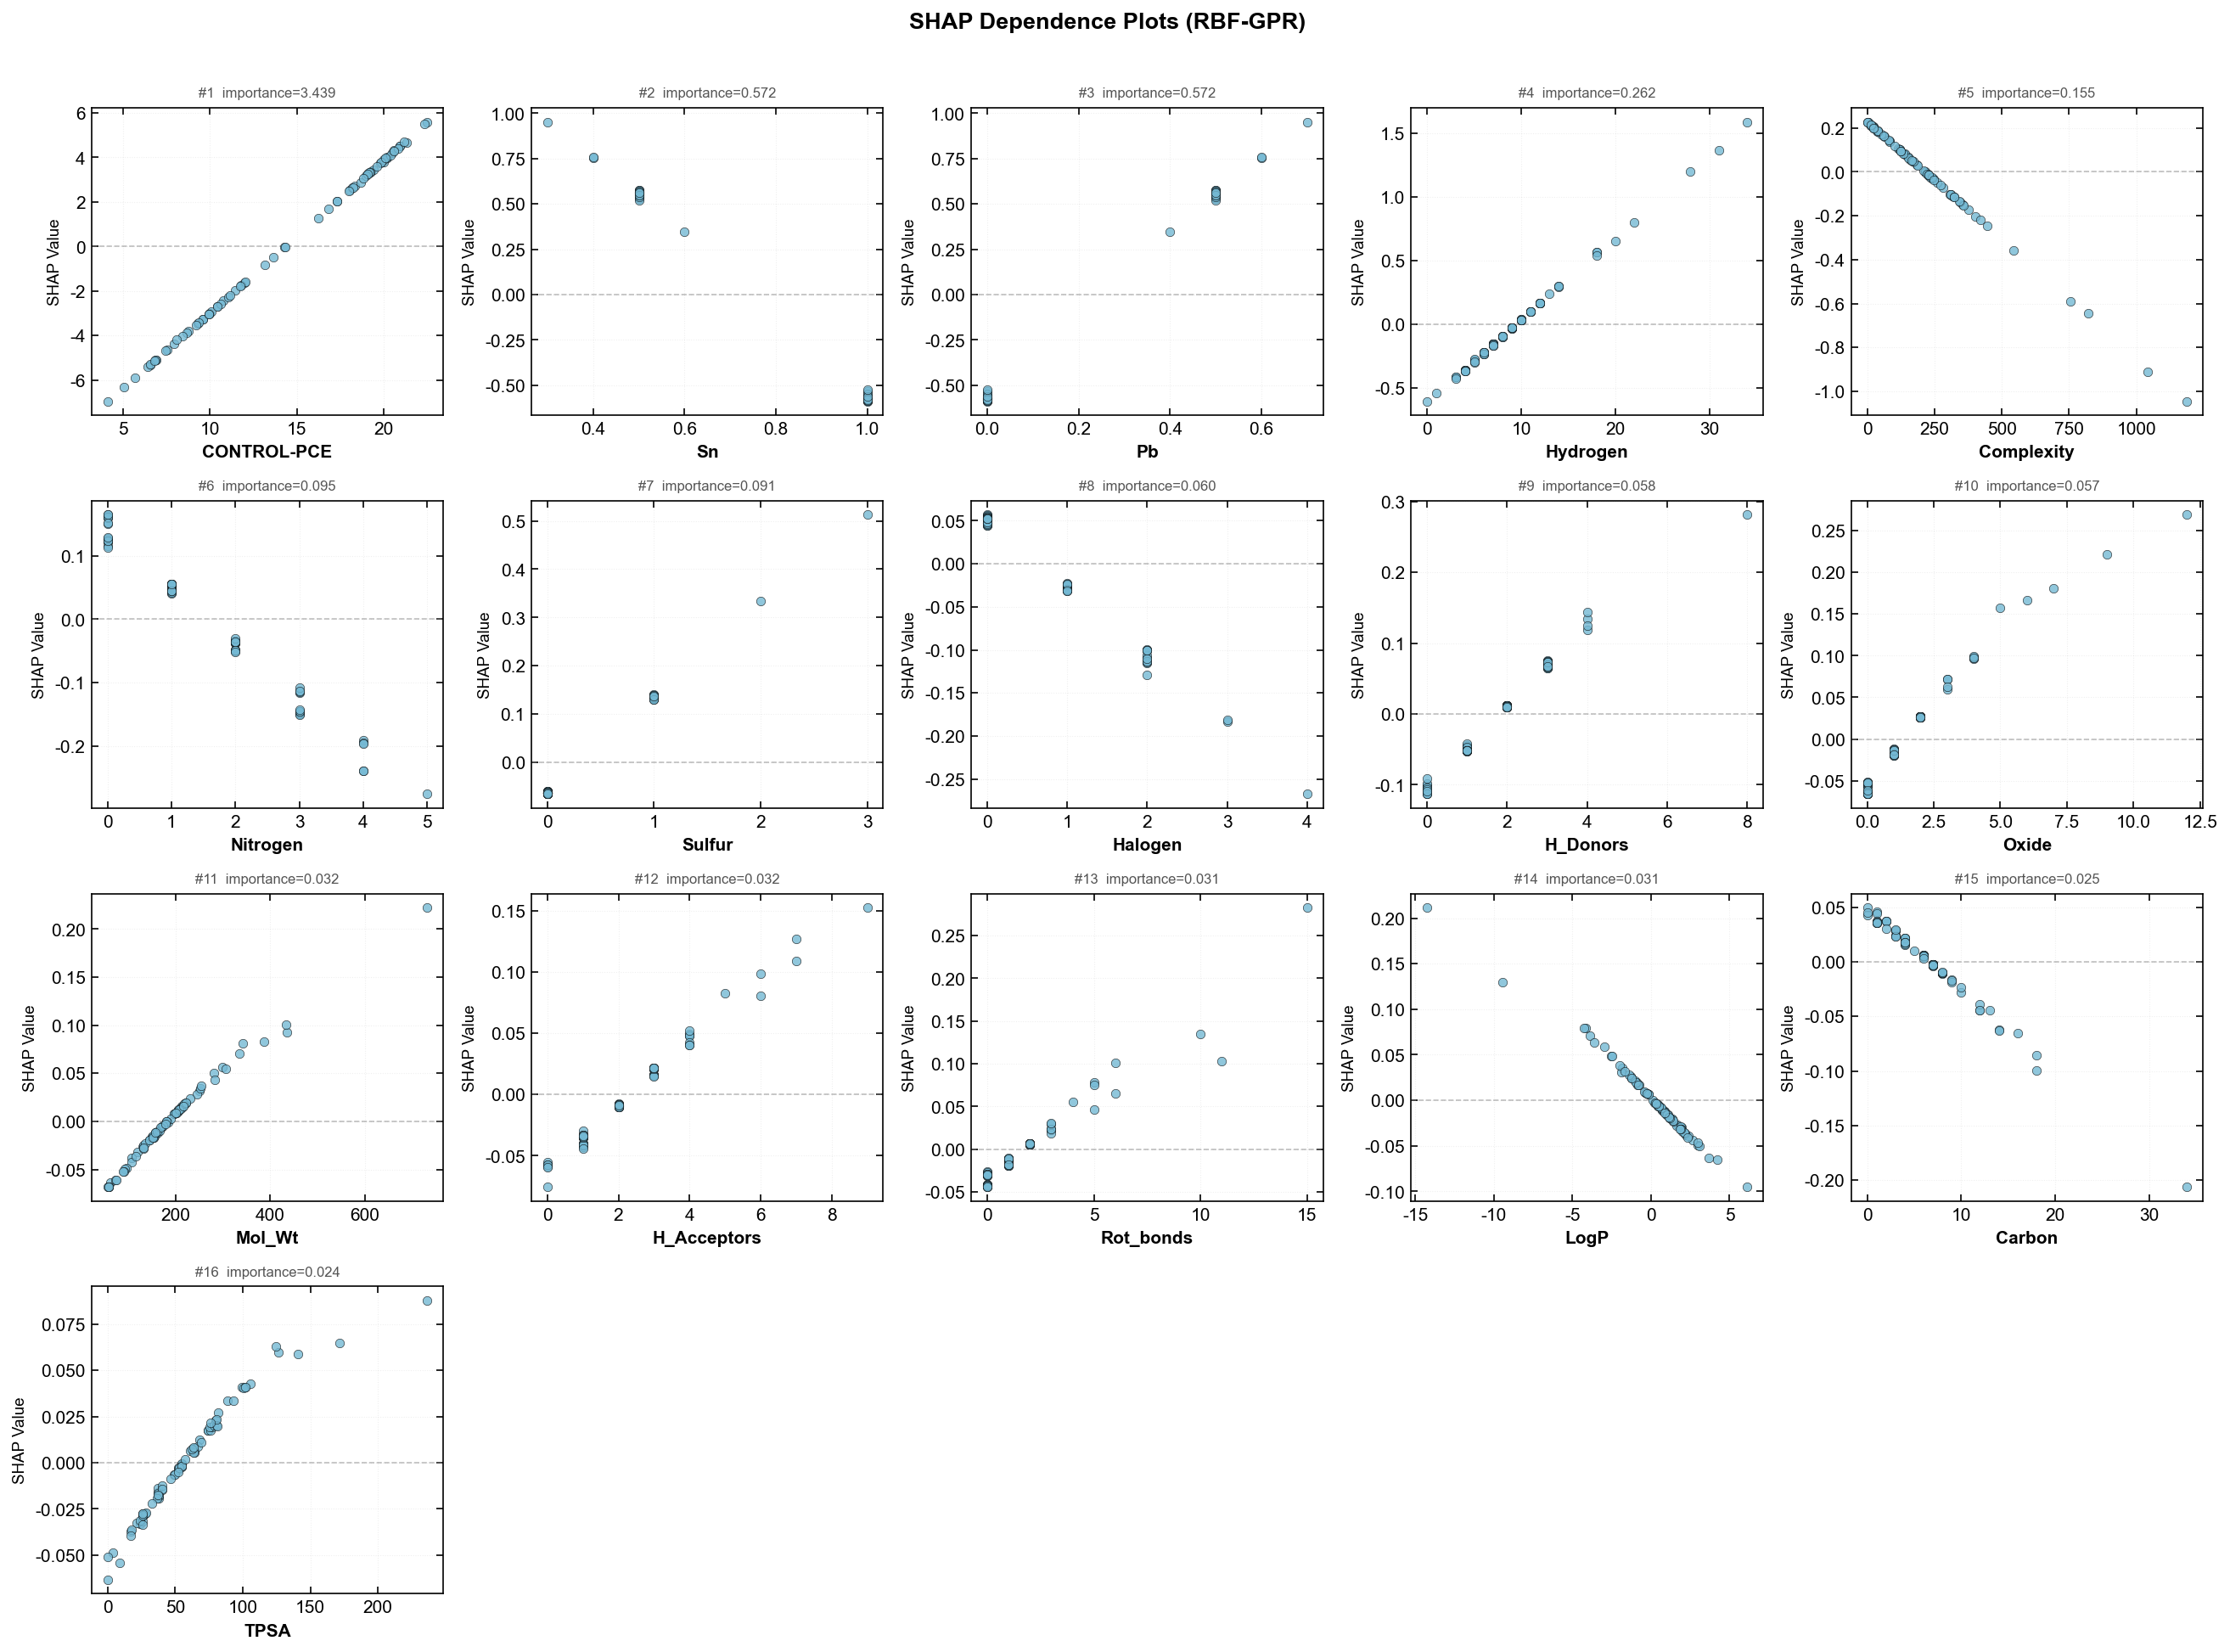

✅ 完成！


In [16]:
  import shap
  import matplotlib.pyplot as plt
  import numpy as np
  import math
  import pandas as pd
  from sklearn.gaussian_process import GaussianProcessRegressor
  from sklearn.gaussian_process.kernels import RBF, ConstantKernel as C

  plt.rcParams.update({
      'font.family': 'Arial',
      'font.size': 10,
      'axes.labelsize': 11,
      'axes.titlesize': 12,
      'xtick.labelsize': 10,
      'ytick.labelsize': 10,
      'axes.linewidth': 0.8,
      'xtick.direction': 'in',
      'ytick.direction': 'in',
      'xtick.top': True,
      'ytick.right': True
  })

  # ========== 1. 训练 RBF-GPR ==========
  print("训练 RBF-GPR 模型...")

  rbf_kernel = C(1.0, (1e-3, 1e3)) * RBF(
      length_scale=1.0,
      length_scale_bounds=(1e-3, 1e3)
  )

  rbf_gpr = GaussianProcessRegressor(
      kernel=rbf_kernel,
      alpha=0.1,
      n_restarts_optimizer=10,
      normalize_y=True,
      random_state=42
  )
  rbf_gpr.fit(X_train, y_train)
  print("训练完成！核函数:", rbf_gpr.kernel_)

  # ========== 2. 计算 SHAP 值 ==========
  print("\n计算 SHAP 值（PermutationExplainer）...")

  explainer = shap.PermutationExplainer(
      rbf_gpr.predict,
      X_train,
      max_evals=2 * X_train.shape[1] + 1
  )
  shap_explanation = explainer(X_train)
  shap_values = shap_explanation.values

  print(f"SHAP 矩阵形状: {shap_values.shape}")
  print("\n各特征 SHAP 值范围：")
  for i, col in enumerate(X_train.columns):
      print(f"  {col:20s}: [{shap_values[:, i].min():.4f}, {shap_values[:, i].max():.4f}]")

  # ========== 3. 按重要性排序 ==========
  mean_abs_shap = np.abs(shap_values).mean(axis=0)
  sorted_idx = np.argsort(mean_abs_shap)[::-1]
  num_features = X_train.shape[1]

  # ========== 4. 绘图 ==========
  ncols = 5
  nrows = math.ceil(num_features / ncols)

  fig, axes = plt.subplots(nrows=nrows, ncols=ncols,
                            figsize=(ncols * 3.5, nrows * 3.2), dpi=150)
  axes = axes.flatten()

  for i, col_i in enumerate(sorted_idx):
      ax = axes[i]
      col_name = X_train.columns[col_i]

      train_idx = X_train.index
      x_vals = X.loc[train_idx, col_name].values
      y_vals = shap_values[:, col_i]

      ax.scatter(
          x_vals, y_vals,
          color='#74B9D4',
          alpha=0.8,
          edgecolor='k',
          linewidth=0.3,
          s=25,
          zorder=3
      )

      ax.axhline(y=0, color='gray', linewidth=0.8, linestyle='--', alpha=0.5)
      ax.set_xlabel(col_name, fontweight='bold', fontsize=10)
      ax.set_ylabel('SHAP Value', fontsize=9)
      ax.set_title(f'#{i+1}  importance={mean_abs_shap[col_i]:.3f}', fontsize=8, color='#555')
      ax.grid(True, alpha=0.2, linestyle=':', linewidth=0.5)
      for spine in ax.spines.values():
          spine.set_linewidth(0.8)

  for j in range(num_features, len(axes)):
      fig.delaxes(axes[j])

  plt.suptitle('SHAP Dependence Plots (RBF-GPR)', fontsize=13, fontweight='bold', y=1.01)
  plt.tight_layout()
  plt.savefig('shap_dependence_rbf_gpr.png', dpi=150, bbox_inches='tight')
  plt.show()
  print("✅ 完成！")

In [17]:
data_pre = pd.read_excel('预测分子.xlsx')
data_pre

,Name,SMILES,
0,2-Bromoethylamine hydrobromide,C(CBr)N.Br,
1,2-Bromoethylamine,C(CBr)N,
2,2-Bromoethylamine monohydrobromide,C(CBr)[NH3+].[Br-],
3,"2,2-Dibromoethan-1-amine hydrochloride",C(C(Br)Br)N.Cl,
4,2-Bromoethylamine hydrochloride,C(CBr)N.Cl,
...,...,...,...
82686,"deuterio N,N-dideuteriosulfamate",[2H]N([2H])S(=O)(=O)O[2H],
82687,Sodium sulfamic acid,NS(=O)(=O)O.[Na+],
82688,Sulfinoazanide,[NH-]S(=O)O,
82689,Manganese(2+);sulfamic acid,NS(=O)(=O)O.[Mn+2],


In [18]:
import pandas as pd

# 1. 读取包含要剔除分子的 Excel 文件
# 假设该文件中存放 SMILES 的列名也是 'SMILES'
data_exclude = pd.read_excel('锡基的收集含c链.xlsx')

# 2. 获取需要剔除的 SMILES 列表（建议进行去重处理以提高匹配效率）
exclude_list = data_exclude['SMILES'].unique()

# 3. 从 data_pre 中过滤掉在 exclude_list 中存在的分子
# ~ 符号表示“取反”，即保留那些 SMILES 不在 exclude_list 中的行
data_filtered = data_pre[~data_pre['SMILES'].isin(exclude_list)].copy()

# 4. (可选) 重置索引并查看结果
data_filtered = data_filtered.reset_index(drop=True)

print(f"原始分子数量: {len(data_pre)}")
print(f"剔除后的分子数量: {len(data_filtered)}")
print(f"共剔除了 {len(data_pre) - len(data_filtered)} 个重复分子")

# 查看前几行
print(data_filtered.head())

原始分子数量: 82691
剔除后的分子数量: 82589
共剔除了 102 个重复分子
                                     Name              SMILES   
0                       2-Bromoethylamine             C(CBr)N   
1      2-Bromoethylamine monohydrobromide  C(CBr)[NH3+].[Br-]   
2  2,2-Dibromoethan-1-amine hydrochloride      C(C(Br)Br)N.Cl   
3         2-Bromoethylamine hydrochloride          C(CBr)N.Cl   
4                       1-Bromoethanamine             CC(N)Br   


In [19]:
import pandas as pd
import numpy as np
from rdkit import Chem
from rdkit.Chem import Descriptors, rdMolDescriptors, Lipinski


smiles_series = data_pre.iloc[:, 1].astype(str)


def calc_features(smiles: str) -> dict:
    if pd.isna(smiles) or smiles.strip() == '':
        mol = None
    else:
        mol = Chem.MolFromSmiles(smiles.strip())
    
    if mol is None:
        return {key: np.nan for key in [
            'Heavy_atoms', 'H_Acceptors', 'H_Donors', 'Rot_bonds', 'Mol_Wt',
            'TPSA', 'LogP', 'Complexity',
            'Carbon', 'Hydrogen', 'Oxide', 'Nitrogen', 'Sulfur', 'Halogen'
        ]}
    
    # 基础描述符（不需要加氢）
    heavy_atoms = rdMolDescriptors.CalcNumHeavyAtoms(mol)
    h_acceptors = Lipinski.NumHAcceptors(mol)
    h_donors = Lipinski.NumHDonors(mol)
    rot_bonds = Lipinski.NumRotatableBonds(mol)
    mol_wt = Descriptors.MolWt(mol)
    tpsa = Descriptors.TPSA(mol)
    logp = Descriptors.MolLogP(mol)
    complexity = Descriptors.BertzCT(mol)

    # 原子计数：需加氢以统计总氢原子数
    mol_with_h = Chem.AddHs(mol)
    carbon = hydrogen = oxide = nitrogen = sulfur = halogen = 0
    for atom in mol_with_h.GetAtoms():
        symbol = atom.GetSymbol()
        if symbol == 'C':
            carbon += 1
        elif symbol == 'H':
            hydrogen += 1
        elif symbol == 'O':
            oxide += 1
        elif symbol == 'N':
            nitrogen += 1
        elif symbol == 'S':
            sulfur += 1
        elif symbol in ('F', 'Cl', 'Br', 'I'):
            halogen += 1

    return {
        'Heavy_atoms': heavy_atoms,
        'H_Acceptors': h_acceptors,
        'H_Donors': h_donors,
        'Rot_bonds': rot_bonds,
        'Mol_Wt': mol_wt,
        'TPSA': tpsa,
        'LogP': logp,
        'Complexity': complexity,
        'Carbon': carbon,
        'Hydrogen': hydrogen,
        'Oxide': oxide,
        'Nitrogen': nitrogen,
        'Sulfur': sulfur,
        'Halogen': halogen
    }

features_pre_list = [calc_features(smi) for smi in smiles_series]

# 合并并保存
desc_df_pre = pd.DataFrame(features_pre_list, index=data_pre.index)
data_pre = pd.concat([data_pre, desc_df_pre], axis=1)


[15:09:29] WARNING: not removing hydrogen atom without neighbors
[15:09:29] Explicit valence for atom # 2 Br, 2, is greater than permitted
[15:09:29] WARNING: not removing hydrogen atom without neighbors
[15:09:29] WARNING: not removing hydrogen atom without neighbors
[15:09:29] Explicit valence for atom # 4 Br, 2, is greater than permitted
[15:09:29] Explicit valence for atom # 5 Br, 2, is greater than permitted
[15:09:29] Explicit valence for atom # 2 Br, 2, is greater than permitted
[15:09:29] WARNING: not removing hydrogen atom without neighbors
[15:09:29] Explicit valence for atom # 1 Br, 3, is greater than permitted
[15:09:29] Explicit valence for atom # 1 Br, 3, is greater than permitted
[15:09:29] WARNING: not removing hydrogen atom without neighbors
[15:09:29] WARNING: not removing hydrogen atom without neighbors
[15:09:29] Explicit valence for atom # 6 Br, 2, is greater than permitted
[15:09:30] Explicit valence for atom # 7 S, 7, is greater than permitted
[15:09:30] WARNING:

In [20]:
data_pre

,Name,SMILES,,Heavy_atoms,H_Acceptors,H_Donors,Rot_bonds,Mol_Wt,TPSA,LogP,Complexity,Carbon,Hydrogen,Oxide,Nitrogen,Sulfur,Halogen
0,2-Bromoethylamine hydrobromide,C(CBr)N.Br,,5.0,1.0,1.0,1.0,204.893000,26.02,0.9179,2.000000,2.0,7.0,0.0,1.0,0.0,2.0
1,2-Bromoethylamine,C(CBr)N,,4.0,1.0,1.0,1.0,123.981000,26.02,0.3400,2.000000,2.0,6.0,0.0,1.0,0.0,1.0
2,2-Bromoethylamine monohydrobromide,C(CBr)[NH3+].[Br-],,5.0,0.0,1.0,1.0,204.893000,27.64,-3.3728,2.000000,2.0,7.0,0.0,1.0,0.0,2.0
3,"2,2-Dibromoethan-1-amine hydrochloride",C(C(Br)Br)N.Cl,,6.0,1.0,1.0,1.0,239.338000,26.02,1.4828,14.000000,2.0,6.0,0.0,1.0,0.0,3.0
4,2-Bromoethylamine hydrochloride,C(CBr)N.Cl,,5.0,1.0,1.0,1.0,160.442000,26.02,0.7618,2.000000,2.0,7.0,0.0,1.0,0.0,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
82686,"deuterio N,N-dideuteriosulfamate",[2H]N([2H])S(=O)(=O)O[2H],,5.0,3.0,2.0,2.0,100.113305,80.39,-1.2521,133.421246,0.0,3.0,3.0,1.0,1.0,0.0
82687,Sodium sulfamic acid,NS(=O)(=O)O.[Na+],,6.0,2.0,2.0,0.0,120.085000,80.39,-4.2481,83.206718,0.0,3.0,3.0,1.0,1.0,0.0
82688,Sulfinoazanide,[NH-]S(=O)O,,4.0,1.0,1.0,0.0,80.088000,61.10,0.1753,23.019550,0.0,2.0,2.0,1.0,1.0,0.0
82689,Manganese(2+);sulfamic acid,NS(=O)(=O)O.[Mn+2],,6.0,2.0,2.0,0.0,152.033000,80.39,-1.2546,83.206718,0.0,3.0,3.0,1.0,1.0,0.0


In [21]:
# 过滤掉 Mol_Wt 大于 300 的行，保留小于或等于 300 的分子
data_pre = data_pre[data_pre['Mol_Wt'] <= 300]

# 或者使用 query 方法（更易读）
# data_pre = data_pre.query('Mol_Wt <= 300')

# 查看过滤后的结果数量和前几行
print(f"过滤后的分子数量: {len(data_pre)}")
print(data_pre.head())

过滤后的分子数量: 67480
                                     Name              SMILES     Heavy_atoms  \
0          2-Bromoethylamine hydrobromide          C(CBr)N.Br             5.0   
1                       2-Bromoethylamine             C(CBr)N             4.0   
2      2-Bromoethylamine monohydrobromide  C(CBr)[NH3+].[Br-]             5.0   
3  2,2-Dibromoethan-1-amine hydrochloride      C(C(Br)Br)N.Cl             6.0   
4         2-Bromoethylamine hydrochloride          C(CBr)N.Cl             5.0   

   H_Acceptors  H_Donors  Rot_bonds   Mol_Wt   TPSA    LogP  Complexity  \
0          1.0       1.0        1.0  204.893  26.02  0.9179         2.0   
1          1.0       1.0        1.0  123.981  26.02  0.3400         2.0   
2          0.0       1.0        1.0  204.893  27.64 -3.3728         2.0   
3          1.0       1.0        1.0  239.338  26.02  1.4828        14.0   
4          1.0       1.0        1.0  160.442  26.02  0.7618         2.0   

   Carbon  Hydrogen  Oxide  Nitrogen  Sulfur  

In [22]:
data_pre.drop(columns=['Heavy_atoms'], inplace=True)

C:\Users\Administrator\AppData\Local\Temp\ipykernel_26068\3981197412.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_pre.drop(columns=['Heavy_atoms'], inplace=True)


In [23]:
data_pre

,Name,SMILES,,H_Acceptors,H_Donors,Rot_bonds,Mol_Wt,TPSA,LogP,Complexity,Carbon,Hydrogen,Oxide,Nitrogen,Sulfur,Halogen
0,2-Bromoethylamine hydrobromide,C(CBr)N.Br,,1.0,1.0,1.0,204.893000,26.02,0.9179,2.000000,2.0,7.0,0.0,1.0,0.0,2.0
1,2-Bromoethylamine,C(CBr)N,,1.0,1.0,1.0,123.981000,26.02,0.3400,2.000000,2.0,6.0,0.0,1.0,0.0,1.0
2,2-Bromoethylamine monohydrobromide,C(CBr)[NH3+].[Br-],,0.0,1.0,1.0,204.893000,27.64,-3.3728,2.000000,2.0,7.0,0.0,1.0,0.0,2.0
3,"2,2-Dibromoethan-1-amine hydrochloride",C(C(Br)Br)N.Cl,,1.0,1.0,1.0,239.338000,26.02,1.4828,14.000000,2.0,6.0,0.0,1.0,0.0,3.0
4,2-Bromoethylamine hydrochloride,C(CBr)N.Cl,,1.0,1.0,1.0,160.442000,26.02,0.7618,2.000000,2.0,7.0,0.0,1.0,0.0,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
82686,"deuterio N,N-dideuteriosulfamate",[2H]N([2H])S(=O)(=O)O[2H],,3.0,2.0,2.0,100.113305,80.39,-1.2521,133.421246,0.0,3.0,3.0,1.0,1.0,0.0
82687,Sodium sulfamic acid,NS(=O)(=O)O.[Na+],,2.0,2.0,0.0,120.085000,80.39,-4.2481,83.206718,0.0,3.0,3.0,1.0,1.0,0.0
82688,Sulfinoazanide,[NH-]S(=O)O,,1.0,1.0,0.0,80.088000,61.10,0.1753,23.019550,0.0,2.0,2.0,1.0,1.0,0.0
82689,Manganese(2+);sulfamic acid,NS(=O)(=O)O.[Mn+2],,2.0,2.0,0.0,152.033000,80.39,-1.2546,83.206718,0.0,3.0,3.0,1.0,1.0,0.0


In [24]:
# pre_mol是将预测后的PCE合并，方便看
pre_mol = data_pre.copy()


In [25]:
data_pre.drop(columns=['SMILES','Name'], inplace=True)

C:\Users\Administrator\AppData\Local\Temp\ipykernel_26068\3365206079.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_pre.drop(columns=['SMILES','Name'], inplace=True)


In [26]:
# 1. 划分数据集
# 假设纯锡基数据的 Pb 含量严格为 0 (如果存在浮点数精度问题，可以改为 X['Pb'] < 1e-5)
X_sn_only = X[X['Pb'] == 0] 

# 假设锡铅混合数据的 Pb 含量大于 0
X_sn_pb_mixed = X[X['Pb'] > 0]

# 2. 统计各个类别的样本数量
count_sn_only = len(X_sn_only)
count_sn_pb_mixed = len(X_sn_pb_mixed)

# 3. 分别计算平均值
mean_sn_only = X_sn_only.mean()
mean_sn_pb_mixed = X_sn_pb_mixed.mean()

# 4. 打印纯锡基数据的特征平均值和数量
print(f"【纯锡基】样本数量: {count_sn_only} 个")
print("【纯锡基】特征平均值 (Pb = 0):")
print("=" * 50)
for feature, mean_value in mean_sn_only.items():
    print(f"{feature:25}: {mean_value:.4f}")

print("\n" + "*" * 50 + "\n") # 添加分隔符以便阅读

# 5. 打印锡铅混合数据的特征平均值和数量
print(f"【锡铅混合】样本数量: {count_sn_pb_mixed} 个")
print("【锡铅混合】特征平均值 (Pb > 0):")
print("=" * 50)
for feature, mean_value in mean_sn_pb_mixed.items():
    print(f"{feature:25}: {mean_value:.4f}")

【纯锡基】样本数量: 47 个
【纯锡基】特征平均值 (Pb = 0):
CONTROL-PCE              : 9.5747
Sn                       : 1.0000
Pb                       : 0.0000
H_Acceptors              : 1.8298
H_Donors                 : 1.6596
Rot_bonds                : 1.8298
Mol_Wt                   : 183.4135
TPSA                     : 49.2155
LogP                     : 0.2772
Complexity               : 193.5003
Carbon                   : 6.4894
Hydrogen                 : 9.7660
Oxide                    : 1.0213
Nitrogen                 : 1.5745
Sulfur                   : 0.2766
Halogen                  : 0.7447

**************************************************

【锡铅混合】样本数量: 51 个
【锡铅混合】特征平均值 (Pb > 0):
CONTROL-PCE              : 19.2580
Sn                       : 0.4902
Pb                       : 0.5098
H_Acceptors              : 2.9804
H_Donors                 : 1.9216
Rot_bonds                : 2.2353
Mol_Wt                   : 207.1482
TPSA                     : 68.3218
LogP                     : -0.1793
Complexity 

In [27]:
data_pre['Sn'] = 0.5   
data_pre['CONTROL-PCE'] = 21.50           
data_pre['Pb'] = 0.5       

C:\Users\Administrator\AppData\Local\Temp\ipykernel_26068\84331835.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_pre['Sn'] = 0.5
C:\Users\Administrator\AppData\Local\Temp\ipykernel_26068\84331835.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_pre['CONTROL-PCE'] = 21.50
C:\Users\Administrator\AppData\Local\Temp\ipykernel_26068\84331835.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead


In [28]:
data_pre

,,H_Acceptors,H_Donors,Rot_bonds,Mol_Wt,TPSA,LogP,Complexity,Carbon,Hydrogen,Oxide,Nitrogen,Sulfur,Halogen,Sn,CONTROL-PCE,Pb
0,,1.0,1.0,1.0,204.893000,26.02,0.9179,2.000000,2.0,7.0,0.0,1.0,0.0,2.0,0.5,21.5,0.5
1,,1.0,1.0,1.0,123.981000,26.02,0.3400,2.000000,2.0,6.0,0.0,1.0,0.0,1.0,0.5,21.5,0.5
2,,0.0,1.0,1.0,204.893000,27.64,-3.3728,2.000000,2.0,7.0,0.0,1.0,0.0,2.0,0.5,21.5,0.5
3,,1.0,1.0,1.0,239.338000,26.02,1.4828,14.000000,2.0,6.0,0.0,1.0,0.0,3.0,0.5,21.5,0.5
4,,1.0,1.0,1.0,160.442000,26.02,0.7618,2.000000,2.0,7.0,0.0,1.0,0.0,2.0,0.5,21.5,0.5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
82686,,3.0,2.0,2.0,100.113305,80.39,-1.2521,133.421246,0.0,3.0,3.0,1.0,1.0,0.0,0.5,21.5,0.5
82687,,2.0,2.0,0.0,120.085000,80.39,-4.2481,83.206718,0.0,3.0,3.0,1.0,1.0,0.0,0.5,21.5,0.5
82688,,1.0,1.0,0.0,80.088000,61.10,0.1753,23.019550,0.0,2.0,2.0,1.0,1.0,0.0,0.5,21.5,0.5
82689,,2.0,2.0,0.0,152.033000,80.39,-1.2546,83.206718,0.0,3.0,3.0,1.0,1.0,0.0,0.5,21.5,0.5


In [29]:
data_pre_aligned = data_pre[X.columns]

In [30]:
# 用训练时的 scaler 对预测数据做同样的归一化
data_pre_scaled_array = scaler.transform(data_pre_aligned)

In [31]:
data_pre_aligned

,CONTROL-PCE,Sn,Pb,H_Acceptors,H_Donors,Rot_bonds,Mol_Wt,TPSA,LogP,Complexity,Carbon,Hydrogen,Oxide,Nitrogen,Sulfur,Halogen
0,21.5,0.5,0.5,1.0,1.0,1.0,204.893000,26.02,0.9179,2.000000,2.0,7.0,0.0,1.0,0.0,2.0
1,21.5,0.5,0.5,1.0,1.0,1.0,123.981000,26.02,0.3400,2.000000,2.0,6.0,0.0,1.0,0.0,1.0
2,21.5,0.5,0.5,0.0,1.0,1.0,204.893000,27.64,-3.3728,2.000000,2.0,7.0,0.0,1.0,0.0,2.0
3,21.5,0.5,0.5,1.0,1.0,1.0,239.338000,26.02,1.4828,14.000000,2.0,6.0,0.0,1.0,0.0,3.0
4,21.5,0.5,0.5,1.0,1.0,1.0,160.442000,26.02,0.7618,2.000000,2.0,7.0,0.0,1.0,0.0,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
82686,21.5,0.5,0.5,3.0,2.0,2.0,100.113305,80.39,-1.2521,133.421246,0.0,3.0,3.0,1.0,1.0,0.0
82687,21.5,0.5,0.5,2.0,2.0,0.0,120.085000,80.39,-4.2481,83.206718,0.0,3.0,3.0,1.0,1.0,0.0
82688,21.5,0.5,0.5,1.0,1.0,0.0,80.088000,61.10,0.1753,23.019550,0.0,2.0,2.0,1.0,1.0,0.0
82689,21.5,0.5,0.5,2.0,2.0,0.0,152.033000,80.39,-1.2546,83.206718,0.0,3.0,3.0,1.0,1.0,0.0


In [32]:
X_predict_NOR = pd.DataFrame(
    data_pre_scaled_array, 
    columns=data_pre_aligned.columns,
    index=data_pre_aligned.index
)

In [33]:
X_predict_NOR

,CONTROL-PCE,Sn,Pb,H_Acceptors,H_Donors,Rot_bonds,Mol_Wt,TPSA,LogP,Complexity,Carbon,Hydrogen,Oxide,Nitrogen,Sulfur,Halogen
0,0.940476,0.285714,0.714286,0.111111,0.125,0.066667,0.219143,0.109975,0.744922,0.001685,0.058824,0.184211,0.000000,0.166667,0.00,0.333333
1,0.940476,0.285714,0.714286,0.111111,0.125,0.066667,0.099215,0.109975,0.716523,0.001685,0.058824,0.157895,0.000000,0.166667,0.00,0.166667
2,0.940476,0.285714,0.714286,0.000000,0.125,0.066667,0.219143,0.116822,0.534068,0.001685,0.058824,0.184211,0.000000,0.166667,0.00,0.333333
3,0.940476,0.285714,0.714286,0.111111,0.125,0.066667,0.270197,0.109975,0.772683,0.011792,0.058824,0.157895,0.000000,0.166667,0.00,0.500000
4,0.940476,0.285714,0.714286,0.111111,0.125,0.066667,0.153258,0.109975,0.737251,0.001685,0.058824,0.184211,0.000000,0.166667,0.00,0.333333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
82686,0.940476,0.285714,0.714286,0.333333,0.250,0.133333,0.063839,0.339772,0.638284,0.112378,0.000000,0.078947,0.250000,0.166667,0.25,0.000000
82687,0.940476,0.285714,0.714286,0.222222,0.250,0.000000,0.093441,0.339772,0.491054,0.070083,0.000000,0.078947,0.250000,0.166667,0.25,0.000000
82688,0.940476,0.285714,0.714286,0.111111,0.125,0.000000,0.034157,0.258242,0.708429,0.019389,0.000000,0.052632,0.166667,0.166667,0.25,0.000000
82689,0.940476,0.285714,0.714286,0.222222,0.250,0.000000,0.140794,0.339772,0.638161,0.070083,0.000000,0.078947,0.250000,0.166667,0.25,0.000000


In [34]:
# 1. 统计并处理 X_predict_NOR 中的缺失值
nan_rows = X_predict_NOR.isna().any(axis=1).sum()

if nan_rows > 0:
    print(f"⚠️ 发现 {nan_rows} 行数据包含 NaN (由于 RDKit 提取特征失败)")
    
    # 方案：使用 0 填充。
    # 因为 X_predict_NOR 是标准化后的数据，0 代表了训练集的平均水平，这是最稳妥的补全方式。
    X_predict_cleaned = X_predict_NOR.fillna(0)
    print("✅ 已将缺失值填充为 0 (特征均值)")
else:
    X_predict_cleaned = X_predict_NOR

# 2. 使用您的 best_gpr 模型进行预测
try:
    # 修改这里：开启 return_std=True 获取预测均值和标准差（不确定度）
    y_pre_pred, y_pre_std = best_gpr.predict(X_predict_cleaned, return_std=True)
    
    # 3. 将结果写回原始 DataFrame pre_mol
    pre_mol['Predicted_PCE_GPR'] = y_pre_pred
    pre_mol['GPR_Uncertainty'] = y_pre_std  # 记录模型的不确定度

    print("🚀 GPR 预测成功！结果与不确定度已存入 pre_mol")
    
    # 展示前 5 行结果
    display(pre_mol[['SMILES', 'Predicted_PCE_GPR', 'GPR_Uncertainty']].head())

except Exception as e:
    print(f"❌ 预测过程中出现其他错误: {e}")

🚀 GPR 预测成功！结果与不确定度已存入 pre_mol


,SMILES,Predicted_PCE_GPR,GPR_Uncertainty
0,C(CBr)N.Br,23.412758,0.435291
1,C(CBr)N,23.364463,0.396545
2,C(CBr)[NH3+].[Br-],23.514861,0.541863
3,C(C(Br)Br)N.Cl,23.240570,0.520137
4,C(CBr)N.Cl,23.380646,0.393375


In [35]:
from rdkit import Chem

def is_simple_salt(smiles):
    """判断是否为简单的有机铵盐（保留）或含金属/多组分混合物（过滤）"""
    if '.' not in smiles:
        return False  # 不含 '.'，不是混合物，不过滤
    parts = smiles.split('.')
    # 过滤含金属离子的复合物（如 [Mn+2], [Cs], [Na+] 等）
    metal_symbols = {'Li','Na','K','Rb','Cs','Mg','Ca','Sr','Ba',
                     'Mn','Fe','Co','Ni','Cu','Zn','Ag','Sn','Pb',
                     'Cd','Hg','Al','Si','B','P','As','Se','Te'}
    for part in parts:
        mol_part = Chem.MolFromSmiles(part)
        if mol_part is None:
            return True  # 无法解析，视为无效，过滤
        for atom in mol_part.GetAtoms():
            if atom.GetSymbol() in metal_symbols:
                return True  # 含金属，过滤
    return False  # 简单的有机盐（如 .Br, .Cl, .[Br-]），保留

# === 1. 数据清洗 ===
# 过滤含金属的复合物，保留有机铵盐（如 C(CBr)N.Br）
clean_mol = pre_mol[~pre_mol['SMILES'].apply(is_simple_salt)]
# 过滤含数字同位素（如 [15N]）的分子
clean_mol = clean_mol[~clean_mol['SMILES'].str.contains(r'\[\d+', regex=True, na=False)]

# === 2. 不确定度过滤（剔除模型的"幻觉"） ===
threshold = clean_mol['GPR_Uncertainty'].median()
reliable_mol = clean_mol[clean_mol['GPR_Uncertainty'] < threshold]

print(f"原始预测总数: {len(pre_mol)}")
print(f"清洗且过滤后，剩余的高可靠性分子数: {len(reliable_mol)}")

# === 3. 排序 ===
data_pre_sorted = reliable_mol.sort_values(by='Predicted_PCE_GPR', ascending=False)


[15:11:30] WARNING: not removing hydrogen atom without neighbors
[15:11:30] WARNING: not removing hydrogen atom without neighbors
[15:11:30] WARNING: not removing hydrogen atom without neighbors
[15:11:30] WARNING: not removing hydrogen atom without neighbors
[15:11:30] WARNING: not removing hydrogen atom without neighbors
[15:11:30] WARNING: not removing hydrogen atom without neighbors
[15:11:30] WARNING: not removing hydrogen atom without neighbors
[15:11:30] WARNING: not removing hydrogen atom without neighbors
[15:11:30] WARNING: not removing hydrogen atom without neighbors
[15:11:30] WARNING: not removing hydrogen atom without neighbors
[15:11:30] WARNING: not removing hydrogen atom without neighbors
[15:11:30] WARNING: not removing hydrogen atom without neighbors
[15:11:30] WARNING: not removing hydrogen atom without neighbors
[15:11:30] WARNING: not removing hydrogen atom without neighbors
[15:11:30] WARNING: not removing hydrogen atom without neighbors
[15:11:30] WARNING: not r

原始预测总数: 67480
清洗且过滤后，剩余的高可靠性分子数: 29753


In [36]:
from rdkit import Chem
import pandas as pd
import numpy as np


# ============================================================
# 1. 直接通过原子连接关系寻找 NH2/NH3+ + COOH/COO-
# ============================================================
def find_amino_acid_sites(mol):
    sites = []

    for carboxyl_c in mol.GetAtoms():

        if carboxyl_c.GetAtomicNum() != 6:
            continue

        double_bond_oxygens = []
        acid_oxygens = []
        alpha_carbons = []

        for bond in carboxyl_c.GetBonds():
            neighbor = bond.GetOtherAtom(carboxyl_c)

            # 羧基中的 C=O
            if (
                neighbor.GetAtomicNum() == 8
                and bond.GetBondType() == Chem.BondType.DOUBLE
            ):
                double_bond_oxygens.append(neighbor)

            # 羧基中的 -OH 或 -O-
            elif (
                neighbor.GetAtomicNum() == 8
                and bond.GetBondType() == Chem.BondType.SINGLE
                and neighbor.GetDegree() == 1
                and (
                    neighbor.GetTotalNumHs() > 0
                    or neighbor.GetFormalCharge() == -1
                )
            ):
                acid_oxygens.append(neighbor)

            # 与羧基相连的 α-C
            elif (
                neighbor.GetAtomicNum() == 6
                and bond.GetBondType() == Chem.BondType.SINGLE
            ):
                alpha_carbons.append(neighbor)

        if not double_bond_oxygens:
            continue

        if not acid_oxygens:
            continue

        if not alpha_carbons:
            continue

        for alpha_c in alpha_carbons:

            for neighbor in alpha_c.GetNeighbors():

                # 真正的 NH2/NH3+：
                # N只有一个重原子邻居，即只与 α-C 相连
                if (
                    neighbor.GetAtomicNum() == 7
                    and neighbor.GetDegree() == 1
                    and neighbor.GetFormalCharge() in (0, 1)
                ):
                    sites.append({
                        "nitrogen": neighbor.GetIdx(),
                        "alpha_carbon": alpha_c.GetIdx(),
                        "carboxyl_carbon": carboxyl_c.GetIdx(),
                        "carbonyl_oxygen": double_bond_oxygens[0].GetIdx(),
                        "acid_oxygen": acid_oxygens[0].GetIdx()
                    })

    return sites


# ============================================================
# 2. 删除 NH2/NH3+ 和 COOH/COO-，保留其余结构
# ============================================================
def remove_amino_and_carboxyl(smiles):

    if pd.isna(smiles) or str(smiles).strip() == "":
        return None, False

    mol = Chem.MolFromSmiles(str(smiles).strip())

    if mol is None:
        return None, False

    sites = find_amino_acid_sites(mol)

    if len(sites) == 0:
        return (
            Chem.MolToSmiles(
                mol,
                canonical=True,
                isomericSmiles=True
            ),
            False
        )

    atoms_to_remove = set()
    alpha_atoms = set()

    for site in sites:
        atoms_to_remove.update([
            site["nitrogen"],
            site["carboxyl_carbon"],
            site["carbonyl_oxygen"],
            site["acid_oxygen"]
        ])

        alpha_atoms.add(site["alpha_carbon"])

    # 计算删除原子后 α-C 的新编号
    new_alpha_indices = set()

    for old_alpha_index in alpha_atoms:
        shift = sum(
            removed_index < old_alpha_index
            for removed_index in atoms_to_remove
        )

        new_alpha_indices.add(old_alpha_index - shift)

    editable_mol = Chem.RWMol(mol)

    for atom_index in sorted(atoms_to_remove, reverse=True):
        editable_mol.RemoveAtom(atom_index)

    new_mol = editable_mol.GetMol()

    # 清除 α-C 原有的手性和显式氢，
    # 让删除的两个键自动由氢补齐
    for alpha_index in new_alpha_indices:

        if alpha_index >= new_mol.GetNumAtoms():
            continue

        alpha_atom = new_mol.GetAtomWithIdx(alpha_index)

        alpha_atom.SetChiralTag(
            Chem.ChiralType.CHI_UNSPECIFIED
        )
        alpha_atom.SetNumExplicitHs(0)
        alpha_atom.SetNoImplicit(False)
        alpha_atom.SetNumRadicalElectrons(0)

    new_mol.UpdatePropertyCache(strict=False)
    Chem.SanitizeMol(new_mol)

    new_smiles = Chem.MolToSmiles(
        new_mol,
        canonical=True,
        isomericSmiles=True
    )

    return new_smiles, True


# ============================================================
# 3. 检索所有已预测分子
# ============================================================
all_predicted = data_pre_sorted.copy()

conversion = all_predicted["SMILES"].apply(
    remove_amino_and_carboxyl
)

conversion_df = pd.DataFrame(
    conversion.tolist(),
    columns=["SMILES_after", "Matched_amino_acid"],
    index=all_predicted.index
)

all_predicted = pd.concat(
    [all_predicted, conversion_df],
    axis=1
)


# ============================================================
# 4. 先检查你截图中的前10个分子
# 第1–7个正常情况下应当显示 True
# ============================================================
print("前10个预测分子的检索结果：")

top10_check_columns = [
    "Name",
    "SMILES",
    "Predicted_PCE_GPR",
    "Matched_amino_acid",
    "SMILES_after"
]

top10_check_columns = [
    col for col in top10_check_columns
    if col in all_predicted.columns
]

display(
    all_predicted[top10_check_columns].head(10)
)


# ============================================================
# 5. 保留所有成功检索的氨基酸分子
# ============================================================
amino_results = all_predicted[
    all_predicted["Matched_amino_acid"]
    & all_predicted["SMILES_after"].notna()
].copy()

print(f"全部已预测分子数量：{len(all_predicted)}")
print(f"成功检索的氨基酸分子数量：{len(amino_results)}")

if amino_results.empty:
    raise ValueError("没有检索到含 NH2/NH3+ 和 COOH/COO- 的分子")


# ============================================================
# 6. 保存删除前的数据
# ============================================================
amino_results["SMILES_before"] = amino_results["SMILES"]

amino_results["Predicted_PCE_before"] = pd.to_numeric(
    amino_results["Predicted_PCE_GPR"],
    errors="coerce"
)


# ============================================================
# 7. 删除旧描述符
# ============================================================
descriptor_columns = [
    "Heavy_atoms",
    "H_Acceptors",
    "H_Donors",
    "Rot_bonds",
    "Mol_Wt",
    "TPSA",
    "LogP",
    "Complexity",
    "Carbon",
    "Hydrogen",
    "Oxide",
    "Nitrogen",
    "Sulfur",
    "Halogen"
]

amino_results = amino_results.drop(
    columns=descriptor_columns,
    errors="ignore"
)

amino_results["SMILES"] = amino_results["SMILES_after"]


# ============================================================
# 8. 重新计算删除官能团后的描述符
# ============================================================
new_descriptor_df = pd.DataFrame(
    [
        calc_features(smiles)
        for smiles in amino_results["SMILES_after"]
    ],
    index=amino_results.index
)

amino_results = pd.concat(
    [amino_results, new_descriptor_df],
    axis=1
)


# ============================================================
# 9. 保持原预测条件
# ============================================================
amino_results["Sn"] = 0.5
amino_results["Pb"] = 0.5
amino_results["CONTROL-PCE"] = 21.50


# ============================================================
# 10. 按训练特征顺序对齐并归一化
# ============================================================
X_removed_raw = amino_results.reindex(
    columns=X.columns
)

X_removed_raw = X_removed_raw.apply(
    pd.to_numeric,
    errors="coerce"
)

valid_rows = ~X_removed_raw.isna().any(axis=1)

amino_results = amino_results.loc[valid_rows].copy()
X_removed_raw = X_removed_raw.loc[valid_rows].copy()

X_removed_scaled = pd.DataFrame(
    scaler.transform(X_removed_raw),
    columns=X.columns,
    index=X_removed_raw.index
)


# ============================================================
# 11. 重新预测
# ============================================================
pce_after, uncertainty_after = best_gpr.predict(
    X_removed_scaled,
    return_std=True
)

amino_results["Predicted_PCE_after"] = pce_after
amino_results["GPR_Uncertainty_after"] = uncertainty_after


# ============================================================
# 12. 计算PCE下降
# 正数表示下降，负数表示上升
# ============================================================
amino_results["PCE_drop"] = (
    amino_results["Predicted_PCE_before"]
    - amino_results["Predicted_PCE_after"]
)

amino_results["PCE_drop_percent"] = (
    amino_results["PCE_drop"]
    / amino_results["Predicted_PCE_before"]
    * 100
)


# ============================================================
# 13. 计算平均结果
# ============================================================
average_before = (
    amino_results["Predicted_PCE_before"].mean()
)

average_after = (
    amino_results["Predicted_PCE_after"].mean()
)

average_drop = (
    amino_results["PCE_drop"].mean()
)

median_drop = (
    amino_results["PCE_drop"].median()
)

drop_count = int(
    (amino_results["PCE_drop"] > 0).sum()
)

rise_count = int(
    (amino_results["PCE_drop"] < 0).sum()
)


print("\n" + "=" * 60)
print("删除 NH2/NH3+ 和 COOH/COO- 后的结果")
print("=" * 60)
print(f"参与统计的分子数量：{len(amino_results)}")
print(f"删除前平均 PCE：{average_before:.4f}")
print(f"删除后平均 PCE：{average_after:.4f}")
print(f"平均 PCE 下降值：{average_drop:.4f}")
print(f"PCE 下降中位数：{median_drop:.4f}")
print(f"PCE 下降的分子数量：{drop_count}")
print(f"PCE 上升的分子数量：{rise_count}")
print("=" * 60)


# ============================================================
# 14. 保持原始预测PCE顺序显示
# ============================================================
amino_acid_removed_results = amino_results.sort_values(
    by="Predicted_PCE_before",
    ascending=False
).reset_index(drop=True)

result_columns = [
    "Name",
    "SMILES_before",
    "SMILES_after",
    "Predicted_PCE_before",
    "Predicted_PCE_after",
    "PCE_drop",
    "PCE_drop_percent",
    "GPR_Uncertainty_after"
]

result_columns = [
    col for col in result_columns
    if col in amino_acid_removed_results.columns
]

display(
    amino_acid_removed_results[result_columns]
)

[15:11:33] WARNING: not removing hydrogen atom without neighbors
[15:11:33] WARNING: not removing hydrogen atom without neighbors
[15:11:33] WARNING: not removing hydrogen atom without neighbors
[15:11:33] WARNING: not removing hydrogen atom without neighbors
[15:11:33] WARNING: not removing hydrogen atom without neighbors
[15:11:33] WARNING: not removing hydrogen atom without neighbors
[15:11:33] WARNING: not removing hydrogen atom without neighbors
[15:11:33] WARNING: not removing hydrogen atom without neighbors
[15:11:33] WARNING: not removing hydrogen atom without neighbors
[15:11:33] WARNING: not removing hydrogen atom without neighbors
[15:11:33] WARNING: not removing hydrogen atom without neighbors
[15:11:33] WARNING: not removing hydrogen atom without neighbors
[15:11:33] WARNING: not removing hydrogen atom without neighbors
[15:11:33] WARNING: not removing hydrogen atom without neighbors
[15:11:33] WARNING: not removing hydrogen atom without neighbors
[15:11:33] WARNING: not r

前10个预测分子的检索结果：


,Name,SMILES,Predicted_PCE_GPR,Matched_amino_acid,SMILES_after
20421,Octylamine acetate,CCCCCCCCN.CC(=O)O,24.590011,False,CC(=O)O.CCCCCCCCN
39792,2-Amino-3-sulfanylpropanoic acid;butylbenzene,CCCCC1=CC=CC=C1.C(C(C(=O)O)N)S,24.543422,True,CCCCc1ccccc1.CCS
4365,2-Amino-3-sulfanylpropanoic acid;methane,C.C.C(C(C(=O)O)N)S,24.542693,True,C.C.CCS
2797,2-Amino-3-sulfanylpropanoic acid;methane,C.C.C(C(C(=O)O)N)S,24.542693,True,C.C.CCS
4448,2-Amino-3-sulfanylpropanoic acid;ethanamine,CCN.C(C(C(=O)O)N)S,24.541128,True,CCN.CCS
2880,2-Amino-3-sulfanylpropanoic acid;ethanamine,CCN.C(C(C(=O)O)N)S,24.541128,True,CCN.CCS
39701,(2S)-2-amino-3-methylbutanoic acid;2-benzylsul...,CC(C)[C@@H](C(=O)O)N.C1=CC=C(C=C1)CSCC(=O)O,24.521621,True,CC(C)C.O=C(O)CSCc1ccccc1
20454,Acetic acid;heptan-1-amine,CCCCCCCN.CC(=O)O,24.504718,False,CC(=O)O.CCCCCCCN
2904,2-Amino-3-sulfanylpropanoic acid;propanoic acid,CCC(=O)O.C(C(C(=O)O)N)S,24.490551,True,CCC(=O)O.CCS
4372,(2R)-2-amino-3-sulfanylpropanoic acid;propanoi...,CCC(=O)O.C([C@@H](C(=O)O)N)S,24.490551,True,CCC(=O)O.CCS


全部已预测分子数量：29753
成功检索的氨基酸分子数量：898


[15:11:44] WARNING: not removing hydrogen atom without neighbors
[15:11:44] WARNING: not removing hydrogen atom without neighbors
[15:11:44] WARNING: not removing hydrogen atom without neighbors
[15:11:44] WARNING: not removing hydrogen atom without neighbors
[15:11:44] WARNING: not removing hydrogen atom without neighbors
[15:11:44] WARNING: not removing hydrogen atom without neighbors
[15:11:44] WARNING: not removing hydrogen atom without neighbors
[15:11:44] WARNING: not removing hydrogen atom without neighbors
[15:11:44] WARNING: not removing hydrogen atom without neighbors
[15:11:44] WARNING: not removing hydrogen atom without neighbors
[15:11:44] WARNING: not removing hydrogen atom without neighbors
[15:11:44] WARNING: not removing hydrogen atom without neighbors



删除 NH2/NH3+ 和 COOH/COO- 后的结果
参与统计的分子数量：898
删除前平均 PCE：23.9997
删除后平均 PCE：23.7540
平均 PCE 下降值：0.2458
PCE 下降中位数：0.2397
PCE 下降的分子数量：898
PCE 上升的分子数量：0


,Name,SMILES_before,SMILES_after,Predicted_PCE_before,Predicted_PCE_after,PCE_drop,PCE_drop_percent,GPR_Uncertainty_after
0,2-Amino-3-sulfanylpropanoic acid;butylbenzene,CCCCC1=CC=CC=C1.C(C(C(=O)O)N)S,CCCCc1ccccc1.CCS,24.543422,24.305007,0.238415,0.971401,0.662293
1,2-Amino-3-sulfanylpropanoic acid;methane,C.C.C(C(C(=O)O)N)S,C.C.CCS,24.542693,24.213775,0.328919,1.340190,0.694852
2,2-Amino-3-sulfanylpropanoic acid;methane,C.C.C(C(C(=O)O)N)S,C.C.CCS,24.542693,24.213775,0.328919,1.340190,0.694852
3,2-Amino-3-sulfanylpropanoic acid;ethanamine,CCN.C(C(C(=O)O)N)S,CCN.CCS,24.541128,24.251159,0.289969,1.181563,0.591803
4,2-Amino-3-sulfanylpropanoic acid;ethanamine,CCN.C(C(C(=O)O)N)S,CCN.CCS,24.541128,24.251159,0.289969,1.181563,0.591803
...,...,...,...,...,...,...,...,...
893,(R)-2-Amino-3-(4-fluoro-3-hydroxyphenyl)propan...,C1=CC(=C(C=C1C[C@H](C(=O)O)N)O)F,CCc1ccc(F)c(O)c1,23.567888,23.307157,0.260731,1.106299,0.407273
894,"Phenylalanine, 2-fluoro-3-hydroxy-",C1=CC(=C(C(=C1)O)F)CC(C(=O)O)N,CCc1cccc(O)c1F,23.567888,23.307157,0.260731,1.106299,0.407273
895,"2-Amino-2-(2-fluoro-3,4-dihydroxyphenyl)acetic...",C1=CC(=C(C(=C1C(C(=O)O)N)F)O)O,Cc1ccc(O)c(O)c1F,23.565255,23.386269,0.178985,0.759531,0.436630
896,Chromium oxamate,C(=O)(C(=O)[O-])N.[Cr],C=O.[Cr],23.455697,23.181582,0.274115,1.168651,0.536386


In [37]:
data_pre_sorted = data_pre_sorted[~data_pre_sorted['SMILES'].str.contains('.', regex=False)].reset_index(drop=True)

In [38]:
data_pre_sorted


,Name,SMILES,,H_Acceptors,H_Donors,Rot_bonds,Mol_Wt,TPSA,LogP,Complexity,Carbon,Hydrogen,Oxide,Nitrogen,Sulfur,Halogen,Predicted_PCE_GPR,GPR_Uncertainty
0,(2R)-2-amino-3-[1-(4-tert-butylphenyl)ethylsul...,CC(C1=CC=C(C=C1)C(C)(C)C)SC[C@@H](C(=O)O)N,,3.0,2.0,5.0,281.421,63.32,3.19020,402.659605,15.0,23.0,2.0,1.0,1.0,0.0,24.454735,0.542336
1,"(2R)-2-amino-3-(3,3-dimethyl-1-phenylbutyl)sul...",CC(C)(C)CC(C1=CC=CC=C1)SC[C@@H](C(=O)O)N,,3.0,2.0,6.0,281.421,63.32,3.30900,380.249379,15.0,23.0,2.0,1.0,1.0,0.0,24.445338,0.537599
2,"(2R)-2-amino-3-[[3-(2,2-dimethylpropyl)phenyl]...",CC(C)(C)CC1=CC(=CC=C1)CSC[C@@H](C(=O)O)N,,3.0,2.0,6.0,281.421,63.32,2.92030,406.291641,15.0,23.0,2.0,1.0,1.0,0.0,24.424206,0.534662
3,(2R)-2-amino-3-[2-(4-propan-2-ylphenyl)propan-...,CC(C)C1=CC=C(C=C1)C(C)(C)SC[C@@H](C(=O)O)N,,3.0,2.0,6.0,281.421,63.32,3.19020,406.169380,15.0,23.0,2.0,1.0,1.0,0.0,24.416771,0.534949
4,2-Amino-3-[(4-tert-butylphenyl)methylsulfanyl]...,CC(C)(C)C1=CC=C(C=C1)CSCC(C(=O)O)N,,3.0,2.0,5.0,267.394,63.32,2.62920,375.494492,14.0,21.0,2.0,1.0,1.0,0.0,24.368126,0.492704
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23172,"3,6-Dichloro-1H-pyrrolo[2,3-b]pyridine",C1=CC(=NC2=C1C(=CN2)Cl)Cl,,1.0,1.0,0.0,187.029,28.68,2.86970,379.837682,7.0,4.0,0.0,2.0,0.0,2.0,22.565589,0.499481
23173,"4,5-Dichloro-1H-pyrrolo[2,3-b]pyridine",C1=CNC2=NC=C(C(=C21)Cl)Cl,,1.0,1.0,0.0,187.029,28.68,2.86970,379.837682,7.0,4.0,0.0,2.0,0.0,2.0,22.565589,0.499481
23174,"3,4-Dichloro-1H-pyrrolo[2,3-b]pyridine",C1=CN=C2C(=C1Cl)C(=CN2)Cl,,1.0,1.0,0.0,187.029,28.68,2.86970,379.837682,7.0,4.0,0.0,2.0,0.0,2.0,22.565589,0.499481
23175,"2-(1H-benzimidazol-2-yl)-2,2-difluoroacetonitrile",C1=CC=C2C(=C1)NC(=N2)C(C#N)(F)F,,2.0,1.0,1.0,193.156,52.47,2.17828,458.977822,9.0,5.0,0.0,3.0,0.0,2.0,22.546218,0.536672


预测分子中的氨基酸端质子化结果
全部已预测分子：23177
检测到氨基酸端的分子：609
本次新质子化分子： 535
原本已经质子化： 74


,Name,SMILES,SMILES_protonated,SMILES_hydrochloride,Predicted_PCE_GPR,Protonation_status
0,(2R)-2-amino-3-[1-(4-tert-butylphenyl)ethylsulfanyl]propanoic acid,CC(C1=CC=C(C=C1)C(C)(C)C)SC[C@@H](C(=O)O)N,CC(SC[C@H]([NH3+])C(=O)O)c1ccc(C(C)(C)C)cc1,CC(SC[C@H]([NH3+])C(=O)O)c1ccc(C(C)(C)C)cc1.[Cl-],24.454735,已质子化
1,"(2R)-2-amino-3-(3,3-dimethyl-1-phenylbutyl)sulfanylpropanoic acid",CC(C)(C)CC(C1=CC=CC=C1)SC[C@@H](C(=O)O)N,CC(C)(C)CC(SC[C@H]([NH3+])C(=O)O)c1ccccc1,CC(C)(C)CC(SC[C@H]([NH3+])C(=O)O)c1ccccc1.[Cl-],24.445338,已质子化
2,"(2R)-2-amino-3-[[3-(2,2-dimethylpropyl)phenyl]methylsulfanyl]propanoic acid",CC(C)(C)CC1=CC(=CC=C1)CSC[C@@H](C(=O)O)N,CC(C)(C)Cc1cccc(CSC[C@H]([NH3+])C(=O)O)c1,CC(C)(C)Cc1cccc(CSC[C@H]([NH3+])C(=O)O)c1.[Cl-],24.424206,已质子化
3,(2R)-2-amino-3-[2-(4-propan-2-ylphenyl)propan-2-ylsulfanyl]propanoic acid,CC(C)C1=CC=C(C=C1)C(C)(C)SC[C@@H](C(=O)O)N,CC(C)c1ccc(C(C)(C)SC[C@H]([NH3+])C(=O)O)cc1,CC(C)c1ccc(C(C)(C)SC[C@H]([NH3+])C(=O)O)cc1.[Cl-],24.416771,已质子化
4,2-Amino-3-[(4-tert-butylphenyl)methylsulfanyl]propanoic acid,CC(C)(C)C1=CC=C(C=C1)CSCC(C(=O)O)N,CC(C)(C)c1ccc(CSCC([NH3+])C(=O)O)cc1,CC(C)(C)c1ccc(CSCC([NH3+])C(=O)O)cc1.[Cl-],24.368126,已质子化
5,(2S)-2-amino-3-[(4-tert-butylphenyl)methylsulfanyl]propanoic acid,CC(C)(C)C1=CC=C(C=C1)CSC[C@H](C(=O)O)N,CC(C)(C)c1ccc(CSC[C@@H]([NH3+])C(=O)O)cc1,CC(C)(C)c1ccc(CSC[C@@H]([NH3+])C(=O)O)cc1.[Cl-],24.368126,已质子化
6,(2R)-2-amino-3-[(4-tert-butylphenyl)methylsulfanyl]propanoic acid,CC(C)(C)C1=CC=C(C=C1)CSC[C@@H](C(=O)O)N,CC(C)(C)c1ccc(CSC[C@H]([NH3+])C(=O)O)cc1,CC(C)(C)c1ccc(CSC[C@H]([NH3+])C(=O)O)cc1.[Cl-],24.368126,已质子化
7,"(2R)-2-amino-3-[(3,5-dimethylphenyl)methylsulfanyl]-3-methylbutanoic acid",CC1=CC(=CC(=C1)CSC(C)(C)[C@@H](C(=O)O)N)C,Cc1cc(C)cc(CSC(C)(C)[C@H]([NH3+])C(=O)O)c1,Cc1cc(C)cc(CSC(C)(C)[C@H]([NH3+])C(=O)O)c1.[Cl-],24.331105,已质子化
8,"(2S)-2-amino-3-[(3,5-dimethylphenyl)methylsulfanyl]-3-methylbutanoic acid",CC1=CC(=CC(=C1)CSC(C)(C)[C@H](C(=O)O)N)C,Cc1cc(C)cc(CSC(C)(C)[C@@H]([NH3+])C(=O)O)c1,Cc1cc(C)cc(CSC(C)(C)[C@@H]([NH3+])C(=O)O)c1.[Cl-],24.331105,已质子化
9,(2R)-2-amino-3-[(4-ethylphenyl)methylsulfanyl]-3-methylbutanoic acid,CCC1=CC=C(C=C1)CSC(C)(C)[C@@H](C(=O)O)N,CCc1ccc(CSC(C)(C)[C@H]([NH3+])C(=O)O)cc1,CCc1ccc(CSC(C)(C)[C@H]([NH3+])C(=O)O)cc1.[Cl-],24.326584,已质子化


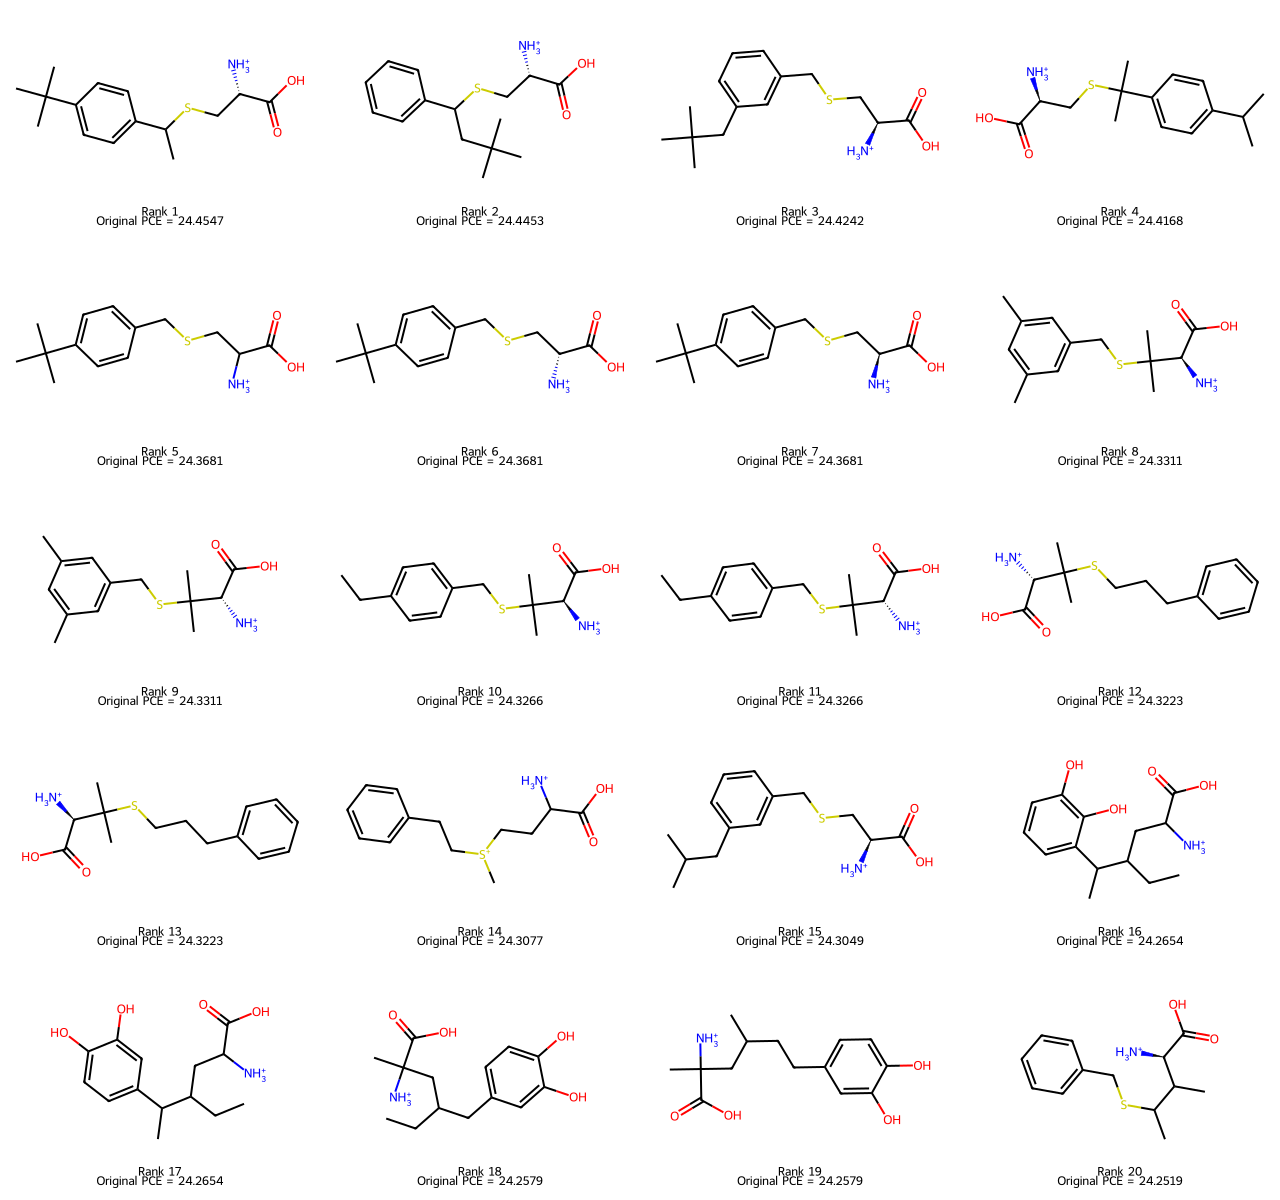

In [39]:
from rdkit import Chem
from rdkit.Chem import Draw
from IPython.display import display
import pandas as pd
import numpy as np


# ============================================================
# 1. 检索真正的氨基酸端
#
# 要求结构为：
# NH2-αC-C(=O)OH
#
# 同时也能识别：
# NH3+-αC-C(=O)O-
#
# 不会误检：
# 仲胺、酰胺、硝基、亚硝基、异氰酸酯和叠氮基
# ============================================================
def find_amino_acid_terminal_sites(mol):
    sites = []

    for carboxyl_carbon in mol.GetAtoms():

        if carboxyl_carbon.GetAtomicNum() != 6:
            continue

        carbonyl_oxygens = []
        acid_oxygens = []
        alpha_carbons = []

        for bond in carboxyl_carbon.GetBonds():
            neighbor = bond.GetOtherAtom(carboxyl_carbon)

            # C=O
            if (
                neighbor.GetAtomicNum() == 8
                and bond.GetBondType() == Chem.BondType.DOUBLE
            ):
                carbonyl_oxygens.append(neighbor)

            # COOH中的OH，或者COO-中的O-
            elif (
                neighbor.GetAtomicNum() == 8
                and bond.GetBondType() == Chem.BondType.SINGLE
                and neighbor.GetDegree() == 1
                and (
                    neighbor.GetTotalNumHs() > 0
                    or neighbor.GetFormalCharge() == -1
                )
            ):
                acid_oxygens.append(neighbor)

            # 与羧基直接相连的α-C
            elif (
                neighbor.GetAtomicNum() == 6
                and bond.GetBondType() == Chem.BondType.SINGLE
            ):
                alpha_carbons.append(neighbor)

        if not carbonyl_oxygens:
            continue

        if not acid_oxygens:
            continue

        for alpha_carbon in alpha_carbons:

            for neighbor in alpha_carbon.GetNeighbors():

                if neighbor.GetAtomicNum() != 7:
                    continue

                # N只有一个重原子邻居，表示NH2或NH3+
                if neighbor.GetDegree() != 1:
                    continue

                if neighbor.GetFormalCharge() not in (0, 1):
                    continue

                sites.append({
                    "nitrogen": neighbor.GetIdx(),
                    "alpha_carbon": alpha_carbon.GetIdx(),
                    "carboxyl_carbon": carboxyl_carbon.GetIdx(),
                    "carbonyl_oxygen": carbonyl_oxygens[0].GetIdx(),
                    "acid_oxygen": acid_oxygens[0].GetIdx()
                })

    # 去重
    unique_sites = []
    seen = set()

    for site in sites:
        key = (
            site["nitrogen"],
            site["alpha_carbon"],
            site["carboxyl_carbon"]
        )

        if key not in seen:
            seen.add(key)
            unique_sites.append(site)

    return unique_sites


# ============================================================
# 2. 把氨基酸端质子化
#
# NH2  -> NH3+
# COO- -> COOH
#
# 同时生成：
# 1. 质子化阳离子SMILES
# 2. 带Cl-的完整盐SMILES
# ============================================================
def protonate_amino_acid_terminal(smiles):

    if pd.isna(smiles) or str(smiles).strip() == "":
        return None, None, False, 0, "无效SMILES"

    mol = Chem.MolFromSmiles(str(smiles).strip())

    if mol is None:
        return None, None, False, 0, "RDKit解析失败"

    sites = find_amino_acid_terminal_sites(mol)

    if len(sites) == 0:
        return None, None, False, 0, "未检测到氨基酸端"

    editable_mol = Chem.RWMol(mol)
    newly_protonated = 0

    for site in sites:

        # ---------- NH2 -> NH3+ ----------
        nitrogen = editable_mol.GetAtomWithIdx(
            site["nitrogen"]
        )

        if nitrogen.GetFormalCharge() != 1:
            newly_protonated += 1

        nitrogen.SetFormalCharge(1)
        nitrogen.SetNumExplicitHs(3)
        nitrogen.SetNoImplicit(True)
        nitrogen.SetNumRadicalElectrons(0)

        # ---------- COO- -> COOH ----------
        acid_oxygen = editable_mol.GetAtomWithIdx(
            site["acid_oxygen"]
        )

        if acid_oxygen.GetFormalCharge() == -1:
            acid_oxygen.SetFormalCharge(0)
            acid_oxygen.SetNumExplicitHs(1)
            acid_oxygen.SetNoImplicit(True)
            acid_oxygen.SetNumRadicalElectrons(0)

    protonated_mol = editable_mol.GetMol()
    protonated_mol.UpdatePropertyCache(strict=False)
    Chem.SanitizeMol(protonated_mol)

    # 只表示质子化后的氨基酸阳离子
    protonated_smiles = Chem.MolToSmiles(
        protonated_mol,
        canonical=True,
        isomericSmiles=True
    )

    # 与论文phenylalanine hydrochloride一致的盐形式
    chloride_counterions = ".".join(
        ["[Cl-]"] * len(sites)
    )

    hydrochloride_smiles = (
        protonated_smiles
        + "."
        + chloride_counterions
    )

    if newly_protonated > 0:
        status = "已质子化"
    else:
        status = "原结构已经质子化"

    return (
        protonated_smiles,
        hydrochloride_smiles,
        True,
        len(sites),
        status
    )


# ============================================================
# 3. 对所有已预测、清洗后的分子进行检索和质子化
# ============================================================
protonation_source = data_pre_sorted.copy()

protonation_results = protonation_source["SMILES"].apply(
    protonate_amino_acid_terminal
)

protonation_df = pd.DataFrame(
    protonation_results.tolist(),
    columns=[
        "SMILES_protonated",
        "SMILES_hydrochloride",
        "Has_amino_acid_terminal",
        "Terminal_count",
        "Protonation_status"
    ],
    index=protonation_source.index
)

protonation_source = pd.concat(
    [protonation_source, protonation_df],
    axis=1
)

# 只保留含氨基酸端的分子
protonated_amino_acids = protonation_source[
    protonation_source["Has_amino_acid_terminal"]
].copy()

# 保持原预测PCE从高到低
protonated_amino_acids = protonated_amino_acids.sort_values(
    by="Predicted_PCE_GPR",
    ascending=False
).reset_index(drop=True)


# ============================================================
# 4. 输出统计和SMILES
# ============================================================
print("=" * 70)
print("预测分子中的氨基酸端质子化结果")
print("=" * 70)
print(f"全部已预测分子：{len(protonation_source)}")
print(f"检测到氨基酸端的分子：{len(protonated_amino_acids)}")
print(
    "本次新质子化分子：",
    (protonated_amino_acids["Protonation_status"] == "已质子化").sum()
)
print(
    "原本已经质子化：",
    (
        protonated_amino_acids["Protonation_status"]
        == "原结构已经质子化"
    ).sum()
)
print("=" * 70)

display_columns = [
    "Name",
    "SMILES",
    "SMILES_protonated",
    "SMILES_hydrochloride",
    "Predicted_PCE_GPR",
    "Protonation_status"
]

display_columns = [
    col for col in display_columns
    if col in protonated_amino_acids.columns
]

pd.set_option("display.max_colwidth", None)

display(
    protonated_amino_acids[display_columns].head(30)
)


# ============================================================
# 5. 绘制PCE最高的前20个质子化结构
# ============================================================
preview_df = protonated_amino_acids.head(20).copy()

preview_molecules = []
preview_legends = []

for rank, row in preview_df.iterrows():

    mol = Chem.MolFromSmiles(
        row["SMILES_protonated"]
    )

    if mol is None:
        continue

    preview_molecules.append(mol)

    if "Predicted_PCE_GPR" in row:
        legend = (
            f"Rank {rank + 1}\n"
            f"Original PCE = {row['Predicted_PCE_GPR']:.4f}"
        )
    else:
        legend = f"Rank {rank + 1}"

    preview_legends.append(legend)

if preview_molecules:

    structure_image = Draw.MolsToGridImage(
        preview_molecules,
        molsPerRow=4,
        subImgSize=(320, 240),
        legends=preview_legends,
        useSVG=False
    )

    display(structure_image)
else:
    print("没有可绘制的质子化结构")


氨基酸端质子化后的PCE预测结果
参与预测的分子数量：609
质子化前平均PCE：23.9371
仅NH3+形式平均PCE：24.0048
仅NH3+形式平均变化：+0.0677
完整盐NH3+·Cl-平均PCE：24.0387
完整盐形式平均变化：+0.1017


,Name,SMILES,SMILES_protonated,SMILES_hydrochloride,PCE_before_protonation,PCE_after_protonation,PCE_change_after_protonation,Uncertainty_after_protonation,PCE_hydrochloride,PCE_change_hydrochloride,Uncertainty_hydrochloride,Out_of_range_features
0,(2R)-2-amino-3-[1-(4-tert-butylphenyl)ethylsulfanyl]propanoic acid,CC(C1=CC=C(C=C1)C(C)(C)C)SC[C@@H](C(=O)O)N,CC(SC[C@H]([NH3+])C(=O)O)c1ccc(C(C)(C)C)cc1,CC(SC[C@H]([NH3+])C(=O)O)c1ccc(C(C)(C)C)cc1.[Cl-],24.454735,24.517083,0.062348,0.593316,24.538596,0.083860,0.664020,0.0
1,"(2R)-2-amino-3-(3,3-dimethyl-1-phenylbutyl)sulfanylpropanoic acid",CC(C)(C)CC(C1=CC=CC=C1)SC[C@@H](C(=O)O)N,CC(C)(C)CC(SC[C@H]([NH3+])C(=O)O)c1ccccc1,CC(C)(C)CC(SC[C@H]([NH3+])C(=O)O)c1ccccc1.[Cl-],24.445338,24.508153,0.062815,0.580513,24.529393,0.084054,0.646926,0.0
2,"(2R)-2-amino-3-[[3-(2,2-dimethylpropyl)phenyl]methylsulfanyl]propanoic acid",CC(C)(C)CC1=CC(=CC=C1)CSC[C@@H](C(=O)O)N,CC(C)(C)Cc1cccc(CSC[C@H]([NH3+])C(=O)O)c1,CC(C)(C)Cc1cccc(CSC[C@H]([NH3+])C(=O)O)c1.[Cl-],24.424206,24.486780,0.062575,0.582722,24.506564,0.082358,0.660433,0.0
3,(2R)-2-amino-3-[2-(4-propan-2-ylphenyl)propan-2-ylsulfanyl]propanoic acid,CC(C)C1=CC=C(C=C1)C(C)(C)SC[C@@H](C(=O)O)N,CC(C)c1ccc(C(C)(C)SC[C@H]([NH3+])C(=O)O)cc1,CC(C)c1ccc(C(C)(C)SC[C@H]([NH3+])C(=O)O)cc1.[Cl-],24.416771,24.479373,0.062602,0.580497,24.499762,0.082991,0.650893,0.0
4,(2R)-2-amino-3-[(4-tert-butylphenyl)methylsulfanyl]propanoic acid,CC(C)(C)C1=CC=C(C=C1)CSC[C@@H](C(=O)O)N,CC(C)(C)c1ccc(CSC[C@H]([NH3+])C(=O)O)cc1,CC(C)(C)c1ccc(CSC[C@H]([NH3+])C(=O)O)cc1.[Cl-],24.368126,24.431554,0.063428,0.543360,24.455732,0.087606,0.623469,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
604,2-Amino-3-(4-fluoro-3-hydroxyphenyl)propanoic acid,C1=CC(=C(C=C1CC(C(=O)O)N)O)F,[NH3+]C(Cc1ccc(F)c(O)c1)C(=O)O,[NH3+]C(Cc1ccc(F)c(O)c1)C(=O)O.[Cl-],23.567888,23.636241,0.068354,0.430558,23.667255,0.099367,0.598418,0.0
605,(R)-2-Amino-3-(4-fluoro-3-hydroxyphenyl)propanoic acid,C1=CC(=C(C=C1C[C@H](C(=O)O)N)O)F,[NH3+][C@H](Cc1ccc(F)c(O)c1)C(=O)O,[NH3+][C@H](Cc1ccc(F)c(O)c1)C(=O)O.[Cl-],23.567888,23.636241,0.068354,0.430558,23.667255,0.099367,0.598418,0.0
606,2-Fluoro-3-hydroxy-D-phenylalanine,C1=CC(=C(C(=C1)O)F)C[C@H](C(=O)O)N,[NH3+][C@H](Cc1cccc(O)c1F)C(=O)O,[NH3+][C@H](Cc1cccc(O)c1F)C(=O)O.[Cl-],23.567888,23.636241,0.068354,0.430558,23.667255,0.099367,0.598418,0.0
607,[1-Carboxy-2-(2-fluoro-5-hydroxyphenyl)ethyl]azanium,C1=CC(=C(C=C1O)CC(C(=O)O)[NH3+])F,[NH3+]C(Cc1cc(O)ccc1F)C(=O)O,[NH3+]C(Cc1cc(O)ccc1F)C(=O)O.[Cl-],23.636241,23.636241,0.000000,0.430558,23.667255,0.031014,0.598418,0.0


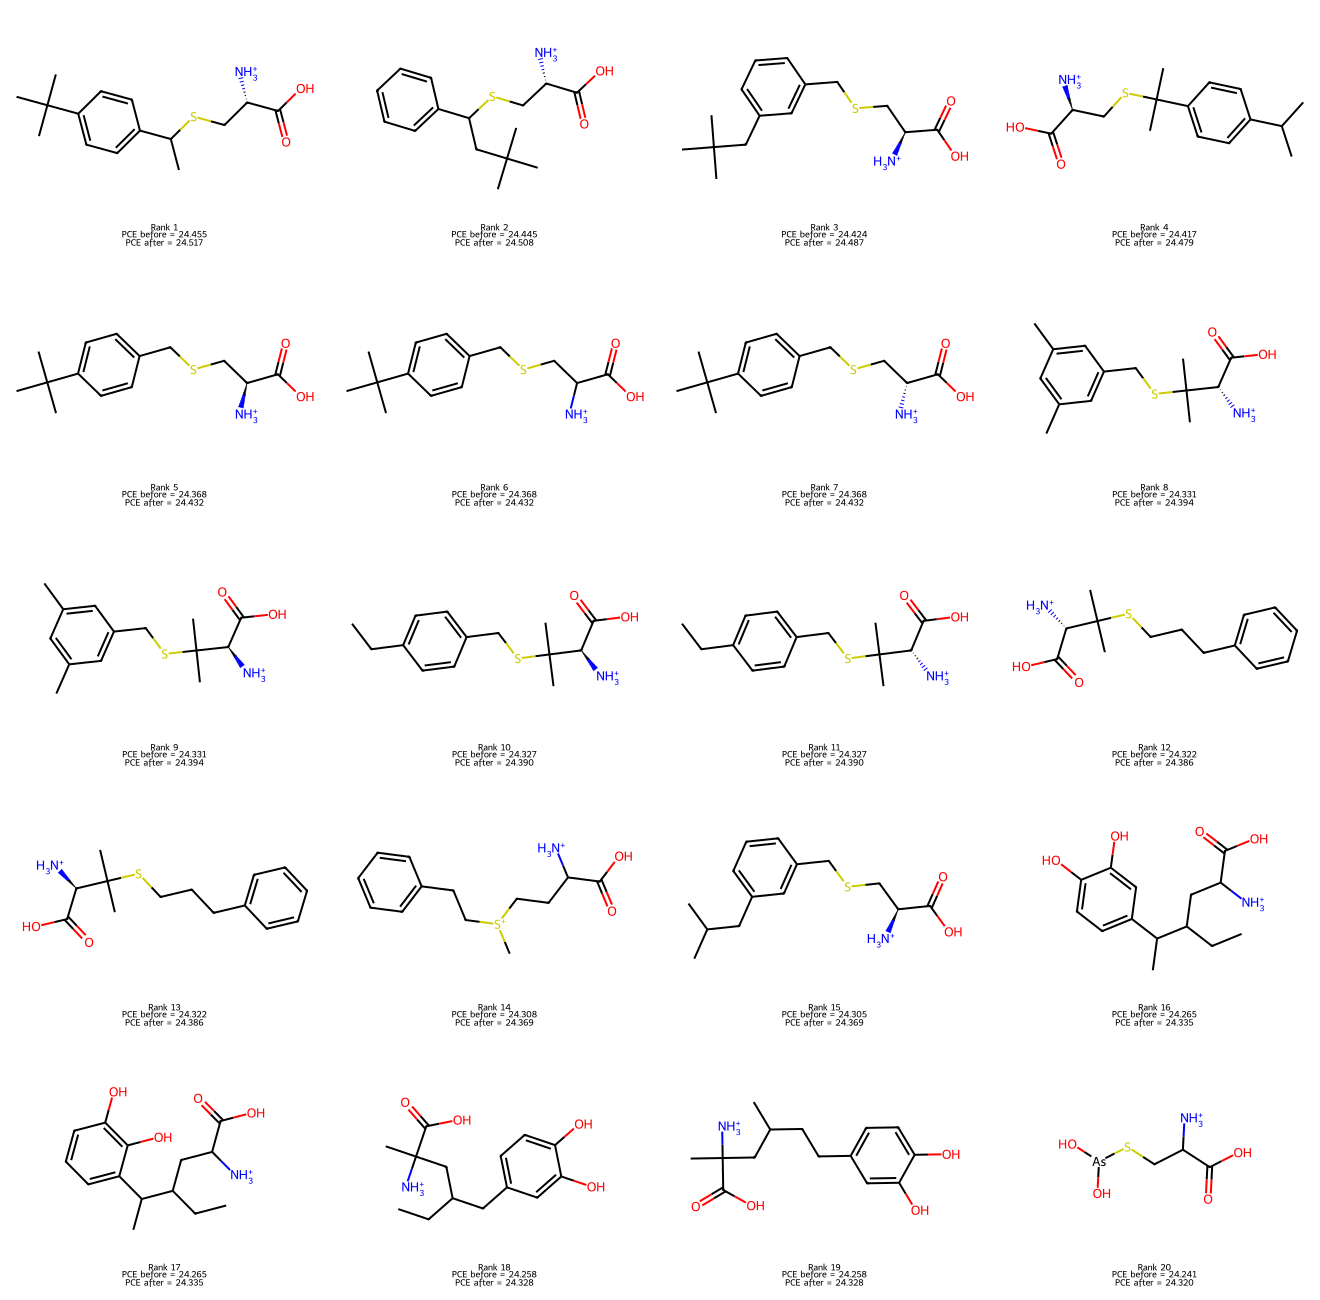

In [40]:
# ============================================================
# 预测质子化后分子的 PCE
# 放在生成 protonated_amino_acids 的代码单元后面
# ============================================================

import pandas as pd
import numpy as np
from rdkit import Chem
from rdkit.Chem import Draw
from IPython.display import display


def predict_new_smiles(smiles_series):
    """
    使用当前 notebook 中已有的：
    calc_features、X、scaler、best_gpr
    预测一批新SMILES的PCE。
    """

    # 重新计算RDKit描述符
    descriptor_df = pd.DataFrame(
        [
            calc_features(smiles)
            for smiles in smiles_series
        ],
        index=smiles_series.index
    )

    # 设置与原预测完全相同的器件条件
    descriptor_df["Sn"] = 0.5
    descriptor_df["Pb"] = 0.5
    descriptor_df["CONTROL-PCE"] = 21.50

    # 严格按照模型训练时的列顺序排列
    model_input_raw = descriptor_df.reindex(
        columns=X.columns
    )

    model_input_raw = model_input_raw.apply(
        pd.to_numeric,
        errors="coerce"
    )

    valid_rows = ~model_input_raw.isna().any(axis=1)

    pce_result = pd.Series(
        np.nan,
        index=smiles_series.index,
        dtype=float
    )

    uncertainty_result = pd.Series(
        np.nan,
        index=smiles_series.index,
        dtype=float
    )

    out_of_range_result = pd.Series(
        np.nan,
        index=smiles_series.index,
        dtype=float
    )

    if valid_rows.any():

        valid_raw = model_input_raw.loc[valid_rows]

        # 检查有多少特征超出训练集范围
        out_of_range_result.loc[valid_rows] = (
            valid_raw.lt(X.min())
            | valid_raw.gt(X.max())
        ).sum(axis=1)

        # 使用训练时的scaler归一化
        valid_scaled = pd.DataFrame(
            scaler.transform(valid_raw),
            columns=X.columns,
            index=valid_raw.index
        )

        # 使用当前最佳GPR模型重新预测
        predicted_pce, predicted_std = best_gpr.predict(
            valid_scaled,
            return_std=True
        )

        pce_result.loc[valid_rows] = predicted_pce
        uncertainty_result.loc[valid_rows] = predicted_std

    return (
        pce_result,
        uncertainty_result,
        out_of_range_result
    )


# ============================================================
# 1. 预测只将 NH2 变成 NH3+ 后的分子
# ============================================================
(
    pce_protonated,
    uncertainty_protonated,
    out_of_range_protonated
) = predict_new_smiles(
    protonated_amino_acids["SMILES_protonated"]
)

protonated_amino_acids["PCE_before_protonation"] = pd.to_numeric(
    protonated_amino_acids["Predicted_PCE_GPR"],
    errors="coerce"
)

protonated_amino_acids["PCE_after_protonation"] = (
    pce_protonated
)

protonated_amino_acids["Uncertainty_after_protonation"] = (
    uncertainty_protonated
)

protonated_amino_acids["Out_of_range_features"] = (
    out_of_range_protonated
)

# 正数表示质子化后PCE升高
# 负数表示质子化后PCE降低
protonated_amino_acids["PCE_change_after_protonation"] = (
    protonated_amino_acids["PCE_after_protonation"]
    - protonated_amino_acids["PCE_before_protonation"]
)


# ============================================================
# 2. 同时预测完整盐形式：NH3+ + Cl-
# ============================================================
(
    pce_hydrochloride,
    uncertainty_hydrochloride,
    out_of_range_hydrochloride
) = predict_new_smiles(
    protonated_amino_acids["SMILES_hydrochloride"]
)

protonated_amino_acids["PCE_hydrochloride"] = (
    pce_hydrochloride
)

protonated_amino_acids["Uncertainty_hydrochloride"] = (
    uncertainty_hydrochloride
)

protonated_amino_acids["PCE_change_hydrochloride"] = (
    protonated_amino_acids["PCE_hydrochloride"]
    - protonated_amino_acids["PCE_before_protonation"]
)


# ============================================================
# 3. 输出总体平均值
# ============================================================
average_before = (
    protonated_amino_acids["PCE_before_protonation"].mean()
)

average_protonated = (
    protonated_amino_acids["PCE_after_protonation"].mean()
)

average_hydrochloride = (
    protonated_amino_acids["PCE_hydrochloride"].mean()
)

average_change_protonated = (
    protonated_amino_acids[
        "PCE_change_after_protonation"
    ].mean()
)

average_change_hydrochloride = (
    protonated_amino_acids[
        "PCE_change_hydrochloride"
    ].mean()
)

print("\n" + "=" * 70)
print("氨基酸端质子化后的PCE预测结果")
print("=" * 70)
print(f"参与预测的分子数量：{len(protonated_amino_acids)}")
print(f"质子化前平均PCE：{average_before:.4f}")
print(f"仅NH3+形式平均PCE：{average_protonated:.4f}")
print(f"仅NH3+形式平均变化：{average_change_protonated:+.4f}")
print(f"完整盐NH3+·Cl-平均PCE：{average_hydrochloride:.4f}")
print(f"完整盐形式平均变化：{average_change_hydrochloride:+.4f}")
print("=" * 70)


# ============================================================
# 4. 按质子化后的PCE从高到低排列
# ============================================================
protonated_pce_results = protonated_amino_acids.sort_values(
    by="PCE_after_protonation",
    ascending=False
).reset_index(drop=True)

result_columns = [
    "Name",
    "SMILES",
    "SMILES_protonated",
    "SMILES_hydrochloride",
    "PCE_before_protonation",
    "PCE_after_protonation",
    "PCE_change_after_protonation",
    "Uncertainty_after_protonation",
    "PCE_hydrochloride",
    "PCE_change_hydrochloride",
    "Uncertainty_hydrochloride",
    "Out_of_range_features"
]

result_columns = [
    col for col in result_columns
    if col in protonated_pce_results.columns
]

pd.set_option("display.max_colwidth", None)

display(
    protonated_pce_results[result_columns]
)


# ============================================================
# 5. 绘制质子化后PCE最高的前20个结构
# ============================================================
preview_df = protonated_pce_results.head(20)

molecules = []
legends = []

for rank, row in preview_df.iterrows():

    mol = Chem.MolFromSmiles(
        row["SMILES_protonated"]
    )

    if mol is None:
        continue

    molecules.append(mol)

    legends.append(
        f"Rank {rank + 1}\n"
        f"PCE before = {row['PCE_before_protonation']:.3f}\n"
        f"PCE after = {row['PCE_after_protonation']:.3f}"
    )

if molecules:

    image = Draw.MolsToGridImage(
        molecules,
        molsPerRow=4,
        subImgSize=(330, 260),
        legends=legends,
        useSVG=False
    )

    display(image)

In [41]:
import pandas as pd
from rdkit import Chem
from IPython.display import display

# ============================================================
# 1. 自动寻找上一段生成的质子化结果表
# ============================================================

_candidates = [
    (name, obj)
    for name, obj in globals().items()
    if (
        isinstance(obj, pd.DataFrame)
        and name not in {'compare_df', 'summary_df'}
        and {
            'SMILES_protonated',
            'PCE_after_protonation'
        }.issubset(obj.columns)
    )
]

if not _candidates:
    raise NameError(
        "没有找到包含 SMILES_protonated 和 "
        "PCE_after_protonation 的结果表"
    )

_source_name, source_df = max(
    _candidates,
    key=lambda item: len(item[1])
)

compare_df = source_df.copy().reset_index(drop=True)

print(
    f"读取的数据表：{_source_name}，"
    f"分子数量：{len(compare_df)}"
)


# ============================================================
# 2. 定位 NH3+–Cα–COOH 结构
# ============================================================

carboxyl_query = Chem.MolFromSmarts(
    '[CX3](=[OX1])[$([OX2H1]),$([O-])]'
)


def find_amino_acid_end(mol):
    """
    返回：
    N原子、Cα、羧基C、两个羧基O的原子索引
    """

    if mol is None:
        return None

    matches = mol.GetSubstructMatches(carboxyl_query)

    for carboxyl_c, oxygen_1, oxygen_2 in matches:

        carboxyl_atom = mol.GetAtomWithIdx(carboxyl_c)

        for alpha_atom in carboxyl_atom.GetNeighbors():

            if alpha_atom.GetAtomicNum() != 6:
                continue

            if alpha_atom.GetIdx() in (oxygen_1, oxygen_2):
                continue

            for nitrogen_atom in alpha_atom.GetNeighbors():

                if nitrogen_atom.GetAtomicNum() != 7:
                    continue

                if nitrogen_atom.GetFormalCharge() != 1:
                    continue

                if nitrogen_atom.GetDegree() != 1:
                    continue

                bond = mol.GetBondBetweenAtoms(
                    alpha_atom.GetIdx(),
                    nitrogen_atom.GetIdx()
                )

                if bond.GetBondType() != Chem.BondType.SINGLE:
                    continue

                return (
                    nitrogen_atom.GetIdx(),
                    alpha_atom.GetIdx(),
                    carboxyl_c,
                    oxygen_1,
                    oxygen_2
                )

    return None


# ============================================================
# 3. 删除官能团
# ============================================================

def remove_amino_acid_group(smiles, group):
    """
    group='COOH'：
    只去掉 COOH，保留 NH3+

    group='NH3'：
    只去掉 NH3+，保留 COOH

    group='BOTH'：
    COOH 和 NH3+ 同时去掉
    """

    mol = Chem.MolFromSmiles(str(smiles))

    if mol is None:
        return None

    match = find_amino_acid_end(mol)

    if match is None:
        return None

    (
        nitrogen_idx,
        alpha_idx,
        carboxyl_c,
        oxygen_1,
        oxygen_2
    ) = match

    rw_mol = Chem.RWMol(mol)

    # 删除官能团后，取消原 Cα 手性
    alpha_atom = rw_mol.GetAtomWithIdx(alpha_idx)

    alpha_atom.SetChiralTag(
        Chem.ChiralType.CHI_UNSPECIFIED
    )

    alpha_atom.SetNumExplicitHs(0)
    alpha_atom.SetNoImplicit(False)

    if group == 'COOH':

        remove_indices = [
            carboxyl_c,
            oxygen_1,
            oxygen_2
        ]

    elif group == 'NH3':

        remove_indices = [
            nitrogen_idx
        ]

    elif group == 'BOTH':

        remove_indices = [
            nitrogen_idx,
            carboxyl_c,
            oxygen_1,
            oxygen_2
        ]

    else:

        raise ValueError(
            "group只能是'COOH'、'NH3'或'BOTH'"
        )

    # 必须按照原子索引从大到小删除
    for atom_idx in sorted(
        remove_indices,
        reverse=True
    ):
        rw_mol.RemoveAtom(atom_idx)

    product = rw_mol.GetMol()

    try:

        Chem.SanitizeMol(product)

        Chem.AssignStereochemistry(
            product,
            cleanIt=True,
            force=True
        )

        return Chem.MolToSmiles(
            product,
            isomericSmiles=True
        )

    except Exception:

        return None


# ============================================================
# 4. 生成三种去官能团后的 SMILES
# ============================================================

compare_df['SMILES_without_COOH'] = (
    compare_df['SMILES_protonated']
    .apply(
        lambda smiles:
        remove_amino_acid_group(
            smiles,
            'COOH'
        )
    )
)

compare_df['SMILES_without_NH3'] = (
    compare_df['SMILES_protonated']
    .apply(
        lambda smiles:
        remove_amino_acid_group(
            smiles,
            'NH3'
        )
    )
)

compare_df['SMILES_without_both'] = (
    compare_df['SMILES_protonated']
    .apply(
        lambda smiles:
        remove_amino_acid_group(
            smiles,
            'BOTH'
        )
    )
)


# ============================================================
# 5. 检查结构修改是否成功
# ============================================================

structure_columns = [
    'SMILES_without_COOH',
    'SMILES_without_NH3',
    'SMILES_without_both'
]

failed_mask = (
    compare_df[structure_columns]
    .isna()
    .any(axis=1)
)

if failed_mask.any():

    print(
        f"有 {failed_mask.sum()} 个分子"
        "无法识别标准 NH3+–Cα–COOH 结构，"
        "已从后续预测中排除。"
    )

    compare_df = (
        compare_df.loc[~failed_mask]
        .reset_index(drop=True)
    )

if len(compare_df) == 0:

    raise ValueError(
        "没有能够完成官能团删除的分子"
    )


# ============================================================
# 6. 用原模型预测修改后分子的 PCE
# ============================================================

def predict_modified_smiles(smiles_series):
    """
    使用前面已经训练好的：
    calc_features
    X
    scaler
    best_gpr
    """

    smiles_series = pd.Series(
        smiles_series
    ).astype(str)

    feature_df = pd.DataFrame(
        [
            calc_features(smiles)
            for smiles in smiles_series
        ],
        index=smiles_series.index
    )

    # 与前面的预测条件保持完全一致
    fixed_conditions = {
        'Sn': 0.5,
        'CONTROL-PCE': 21.50,
        'Pb': 0.5
    }

    for column, value in fixed_conditions.items():

        if column in X.columns:
            feature_df[column] = value

    # 严格按照模型训练时的特征顺序排列
    model_input = feature_df.reindex(
        columns=X.columns
    )

    failed_features = (
        model_input
        .isna()
        .any(axis=1)
    )

    if failed_features.any():

        failed_number = failed_features.sum()

        raise ValueError(
            f"有 {failed_number} 个分子的"
            "特征计算失败"
        )

    model_input_scaled = scaler.transform(
        model_input
    )

    prediction, uncertainty = best_gpr.predict(
        model_input_scaled,
        return_std=True
    )

    return prediction, uncertainty


# ============================================================
# 7. 分别预测三种结构
# ============================================================

pce_without_cooh, std_without_cooh = (
    predict_modified_smiles(
        compare_df['SMILES_without_COOH']
    )
)

pce_without_nh3, std_without_nh3 = (
    predict_modified_smiles(
        compare_df['SMILES_without_NH3']
    )
)

pce_without_both, std_without_both = (
    predict_modified_smiles(
        compare_df['SMILES_without_both']
    )
)


# ============================================================
# 8. 保存预测 PCE 和模型不确定度
# ============================================================

compare_df['PCE_without_COOH'] = (
    pce_without_cooh
)

compare_df['Uncertainty_without_COOH'] = (
    std_without_cooh
)

compare_df['PCE_without_NH3'] = (
    pce_without_nh3
)

compare_df['Uncertainty_without_NH3'] = (
    std_without_nh3
)

compare_df['PCE_without_both'] = (
    pce_without_both
)

compare_df['Uncertainty_without_both'] = (
    std_without_both
)


# ============================================================
# 9. 计算相对于原 NH3+ 质子化形式的 PCE 变化
# ============================================================

baseline_pce = pd.to_numeric(
    compare_df['PCE_after_protonation'],
    errors='coerce'
)

if baseline_pce.isna().any():

    raise ValueError(
        "PCE_after_protonation中存在"
        "无法转换为数值的数据"
    )

compare_df['Delta_PCE_remove_COOH'] = (
    compare_df['PCE_without_COOH']
    - baseline_pce
)

compare_df['Delta_PCE_remove_NH3'] = (
    compare_df['PCE_without_NH3']
    - baseline_pce
)

compare_df['Delta_PCE_remove_both'] = (
    compare_df['PCE_without_both']
    - baseline_pce
)


# ============================================================
# 10. 只显示总的平均预测结果
# ============================================================

summary_df = pd.DataFrame({

    '结构形式': [
        '原NH3+质子化形式',
        '只去掉COOH',
        '只去掉NH3+',
        'COOH和NH3+都去掉'
    ],

    '平均预测PCE': [
        baseline_pce.mean(),

        compare_df[
            'PCE_without_COOH'
        ].mean(),

        compare_df[
            'PCE_without_NH3'
        ].mean(),

        compare_df[
            'PCE_without_both'
        ].mean()
    ],

    '相对原结构平均ΔPCE': [
        0,

        compare_df[
            'Delta_PCE_remove_COOH'
        ].mean(),

        compare_df[
            'Delta_PCE_remove_NH3'
        ].mean(),

        compare_df[
            'Delta_PCE_remove_both'
        ].mean()
    ],

    '平均模型不确定度': [
        0,

        compare_df[
            'Uncertainty_without_COOH'
        ].mean(),

        compare_df[
            'Uncertainty_without_NH3'
        ].mean(),

        compare_df[
            'Uncertainty_without_both'
        ].mean()
    ]
})


display(
    summary_df.style.format({

        '平均预测PCE':
        '{:.4f}',

        '相对原结构平均ΔPCE':
        '{:+.4f}',

        '平均模型不确定度':
        '{:.4f}'
    })
)


# ============================================================
# 11. 保存结果
# ============================================================

summary_df.to_excel(
    '去掉COOH和NH3后的PCE总结果.xlsx',
    index=False
)


print(
    f"预测完成，共统计 "
    f"{len(compare_df)} 个分子。"
)

print(
    "ΔPCE < 0：去掉官能团后预测PCE降低；"
    "ΔPCE > 0：去掉官能团后预测PCE升高。"
)

读取的数据表：protonated_amino_acids，分子数量：609
有 8 个分子无法识别标准 NH3+–Cα–COOH 结构，已从后续预测中排除。


d:\Program Files (x86)\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but GaussianProcessRegressor was fitted with feature names
  warnings.warn(
d:\Program Files (x86)\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but GaussianProcessRegressor was fitted with feature names
  warnings.warn(
d:\Program Files (x86)\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but GaussianProcessRegressor was fitted with feature names
  warnings.warn(


,结构形式,平均预测PCE,相对原结构平均ΔPCE,平均模型不确定度
0,原NH3+质子化形式,24.0042,+0.0000,0.0000
1,只去掉COOH,23.9126,-0.0916,0.4970
2,只去掉NH3+,23.8005,-0.2037,0.5071
3,COOH和NH3+都去掉,23.7042,-0.3000,0.5408


预测完成，共统计 601 个分子。
ΔPCE < 0：去掉官能团后预测PCE降低；ΔPCE > 0：去掉官能团后预测PCE升高。


In [42]:
import pandas as pd
import numpy as np
from rdkit import Chem

# ============================================================
# 运行前需要已经存在：
# calc_features、X、scaler、best_gpr
# ============================================================

# 论文中的三个对应分子
paper_molecules = pd.DataFrame({
    "Structure": [
        "PhA：COOH + NH3+",
        "PEA：去掉COOH，只保留NH3+",
        "PPA：去掉NH3+，只保留COOH",
    ],
    "Name": [
        "L-phenylalanine hydrochloride (PhA)",
        "2-phenethylamine hydrochloride (PEA)",
        "3-phenylpropionic acid (PPA)",
    ],
    "SMILES": [
        "[Cl-].[NH3+][C@@H](Cc1ccccc1)C(=O)O",  # PhA hydrochloride
        "[Cl-].[NH3+]CCc1ccccc1",                # PEA hydrochloride
        "O=C(O)CCc1ccccc1",                      # PPA
    ],
})

# 检查RDKit能否识别
paper_molecules["RDKit_valid"] = paper_molecules["SMILES"].apply(
    lambda smi: Chem.MolFromSmiles(smi) is not None
)

assert paper_molecules["RDKit_valid"].all(), "存在RDKit无法识别的SMILES"

# 计算与你训练时完全相同的描述符
descriptor_df = pd.DataFrame(
    [calc_features(smi) for smi in paper_molecules["SMILES"]],
    index=paper_molecules.index
)

test_df = pd.concat(
    [paper_molecules.copy(), descriptor_df],
    axis=1
)

# 与你原来的预测条件保持一致
test_df["CONTROL-PCE"] = 21.50
test_df["Sn"] = 0.50
test_df["Pb"] = 0.50

# 训练时已经删除了Heavy_atoms
if "Heavy_atoms" in test_df.columns:
    test_df = test_df.drop(columns=["Heavy_atoms"])

# 严格按照训练集特征的名称和顺序排列
missing_columns = [col for col in X.columns if col not in test_df.columns]
if missing_columns:
    raise ValueError(f"缺少训练特征：{missing_columns}")

X_paper = test_df.loc[:, X.columns].copy()

# 检查是否出现缺失值
if X_paper.isna().any().any():
    print("以下特征存在NaN：")
    display(X_paper.loc[:, X_paper.isna().any()])
    raise ValueError("测试分子包含NaN，请先检查描述符")

# 使用训练时的scaler归一化
X_paper_scaled = pd.DataFrame(
    scaler.transform(X_paper),
    columns=X_paper.columns,
    index=X_paper.index
)

# GPR预测均值和不确定度
predicted_pce, predicted_std = best_gpr.predict(
    X_paper_scaled,
    return_std=True
)

test_df["Predicted_PCE"] = predicted_pce
test_df["GPR_std"] = predicted_std

# 计算相对于完整PhA的下降
pha_pce = test_df.loc[
    test_df["Name"].str.contains(r"\(PhA\)", regex=True),
    "Predicted_PCE"
].iloc[0]

test_df["Decrease_vs_PhA"] = pha_pce - test_df["Predicted_PCE"]

# 输出结果
result = test_df[
    [
        "Structure",
        "Name",
        "SMILES",
        "Predicted_PCE",
        "GPR_std",
        "Decrease_vs_PhA",
    ]
].copy()

result = result.sort_values(
    "Predicted_PCE",
    ascending=False
).reset_index(drop=True)

display(
    result.style.format({
        "Predicted_PCE": "{:.4f}",
        "GPR_std": "{:.4f}",
        "Decrease_vs_PhA": "{:+.4f}",
    })
)

# 判断排序是否与论文一致
prediction_order = result["Name"].tolist()

pha_pred = test_df.loc[0, "Predicted_PCE"]
pea_pred = test_df.loc[1, "Predicted_PCE"]
ppa_pred = test_df.loc[2, "Predicted_PCE"]

print("\n论文预期顺序：PhA > PPA > PEA")
print(
    f"模型预测：PhA={pha_pred:.4f}, "
    f"PPA={ppa_pred:.4f}, "
    f"PEA={pea_pred:.4f}"
)

if pha_pred > ppa_pred > pea_pred:
    print("✅ 模型排序与论文一致：PhA > PPA > PEA")
elif pha_pred > pea_pred > ppa_pred:
    print("❌ 模型把PEA和PPA的顺序预测反了：PhA > PEA > PPA")
else:
    print("⚠️ 模型预测顺序与论文存在其他差异")

,Structure,Name,SMILES,Predicted_PCE,GPR_std,Decrease_vs_PhA
0,PhA：COOH + NH3+,L-phenylalanine hydrochloride (PhA),[Cl-].[NH3+][C@@H](Cc1ccccc1)C(=O)O,23.7546,0.5036,+0.0000
1,PEA：去掉COOH，只保留NH3+,2-phenethylamine hydrochloride (PEA),[Cl-].[NH3+]CCc1ccccc1,23.6181,0.5318,+0.1365
2,PPA：去掉NH3+，只保留COOH,3-phenylpropionic acid (PPA),O=C(O)CCc1ccccc1,23.4885,0.4478,+0.2661



论文预期顺序：PhA > PPA > PEA
模型预测：PhA=23.7546, PPA=23.4885, PEA=23.6181
❌ 模型把PEA和PPA的顺序预测反了：PhA > PEA > PPA


In [43]:
import pandas as pd

# 获取前10名并重置索引
top10 = data_pre_sorted.head(10).reset_index(drop=True)
top10.index = top10.index + 1  # 排名从1开始

# 只显示关键列
display_cols = ['Name', 'SMILES', 'Predicted_PCE_GPR']

# 过滤存在的列
display_cols = [c for c in display_cols if c in top10.columns]

# 提取需要展示的数据
final_display = top10[display_cols].copy()

# 手动格式化特定列的数值精度 (不使用 .style)
format_dict = {
    'Predicted_PCE_GPR': '{:.4f}'
    
}

for col, fmt in format_dict.items():
    if col in final_display.columns:
        # 使用 apply 和 lambda 函数将浮点数格式化为字符串
        final_display[col] = final_display[col].apply(lambda x: fmt.format(x))

print("=" * 60)
print("Top 10 Predicted Molecules (无颜色高亮版)")
print("=" * 60)
display(final_display)

Top 10 Predicted Molecules (无颜色高亮版)


,Name,SMILES,Predicted_PCE_GPR
1,(2R)-2-amino-3-[1-(4-tert-butylphenyl)ethylsulfanyl]propanoic acid,CC(C1=CC=C(C=C1)C(C)(C)C)SC[C@@H](C(=O)O)N,24.4547
2,"(2R)-2-amino-3-(3,3-dimethyl-1-phenylbutyl)sulfanylpropanoic acid",CC(C)(C)CC(C1=CC=CC=C1)SC[C@@H](C(=O)O)N,24.4453
3,"(2R)-2-amino-3-[[3-(2,2-dimethylpropyl)phenyl]methylsulfanyl]propanoic acid",CC(C)(C)CC1=CC(=CC=C1)CSC[C@@H](C(=O)O)N,24.4242
4,(2R)-2-amino-3-[2-(4-propan-2-ylphenyl)propan-2-ylsulfanyl]propanoic acid,CC(C)C1=CC=C(C=C1)C(C)(C)SC[C@@H](C(=O)O)N,24.4168
5,2-Amino-3-[(4-tert-butylphenyl)methylsulfanyl]propanoic acid,CC(C)(C)C1=CC=C(C=C1)CSCC(C(=O)O)N,24.3681
6,(2S)-2-amino-3-[(4-tert-butylphenyl)methylsulfanyl]propanoic acid,CC(C)(C)C1=CC=C(C=C1)CSC[C@H](C(=O)O)N,24.3681
7,(2R)-2-amino-3-[(4-tert-butylphenyl)methylsulfanyl]propanoic acid,CC(C)(C)C1=CC=C(C=C1)CSC[C@@H](C(=O)O)N,24.3681
8,3-Benzylsulfanyl-2-(tert-butylamino)propanoic acid,CC(C)(C)NC(CSCC1=CC=CC=C1)C(=O)O,24.3516
9,"4-[4-(tert-Butylamino)butyl]benzene-1,2-diol",CC(C)(C)NCCCCC1=CC(=C(C=C1)O)O,24.3373
10,"(2R)-2-amino-3-[(3,5-dimethylphenyl)methylsulfanyl]-3-methylbutanoic acid",CC1=CC(=CC(=C1)CSC(C)(C)[C@@H](C(=O)O)N)C,24.3311


In [44]:
import pandas as pd

# ----------------------
# 假设你的数据是 data_pre_sorted（和你截图一致）
# ----------------------

# 1. 获取总行数
total = len(data_pre_sorted)

# 2. 计算中间位置（取中间10个）
mid_start = total // 2 - 5
mid_end = total // 2 + 5

# 3. 提取中间10行 + 最后10行
middle_10 = data_pre_sorted.iloc[mid_start : mid_end]
last_10 = data_pre_sorted.tail(10)

# 4. 显示结果
print("="*60)
print("📌 中间 10 个分子")
print("="*60)
print(middle_10)

print("\n" + "="*60)
print("📌 最后 10 个分子")
print("="*60)
print(last_10)

📌 中间 10 个分子
                                                           Name  \
11583                           3-(2-Fluorophenyl)butan-1-amine   
11584        2-(4-Ethenylphenyl)-4-fluoro-3-methylbutanoic acid   
11585  2-methyl-2-{1H-pyrrolo[2,3-b]pyridin-3-yl}propan-1-amine   
11586        2-[Amino(1-benzothiophen-3-yl)methyl]butanenitrile   
11587                                             CID 170692319   
11588                      N-hydroxy-4-(2-phenylethyl)benzamide   
11589              2-[4-[(E)-3-oxobut-1-enyl]phenyl]acetic acid   
11590                                    1-Phenethylamine, (+)-   
11591                                          1-Phenethylamine   
11592                                    1-Phenethylamine, (-)-   

                                    SMILES     H_Acceptors  H_Donors  \
11583                  CC(CCN)C1=CC=CC=C1F             1.0       1.0   
11584      CC(CF)C(C1=CC=C(C=C1)C=C)C(=O)O             1.0       1.0   
11585           CC(C)(CN)C1=CNC2=C

In [45]:
last_10 = data_pre_sorted.tail(10)
print(last_10)

                                                    Name  \
23167        6-Chloro-3-fluoro-1H-pyrrolo[2,3-b]pyridine   
23168        3-chloro-6-fluoro-1H-pyrrolo[2,3-b]pyridine   
23169        4-Chloro-3-fluoro-1H-pyrrolo[2,3-b]pyridine   
23170                           2,5-Dichloro-7-azaindole   
23171             4,6-Dichloro-1H-pyrrolo[2,3-b]pyridine   
23172             3,6-Dichloro-1H-pyrrolo[2,3-b]pyridine   
23173             4,5-Dichloro-1H-pyrrolo[2,3-b]pyridine   
23174             3,4-Dichloro-1H-pyrrolo[2,3-b]pyridine   
23175  2-(1H-benzimidazol-2-yl)-2,2-difluoroacetonitrile   
23176          2-(Cyanomethyl)-5,6-difluorobenzimidazole   

                                SMILES     H_Acceptors  H_Donors  Rot_bonds  \
23167         C1=CC(=NC2=C1C(=CN2)F)Cl             1.0       1.0        0.0   
23168         C1=CC(=NC2=C1C(=CN2)Cl)F             1.0       1.0        0.0   
23169         C1=CN=C2C(=C1Cl)C(=CN2)F             1.0       1.0        0.0   
23170          C1=C2C=C

In [46]:
data_pre_sorted.to_excel('预测结果.xlsx', index=False)